# BikeNodePlanner–OSM overlap

In [89]:
# Run once if your environment is missing packages:
#%pip install geopandas osmnx matplotlib pandas shapely pyogrio
#pixi add pyrosm pyarrow

## Setup

In [90]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox
import pandas as pd
import shapely
from IPython.display import display
from shapely.geometry import box
import requests
from pyrosm import OSM

working_dir = Path.cwd().resolve()

PROJECT_ROOT = working_dir.parent if working_dir.name == "osm_data_exploration" else working_dir

DENMARK_OSM_DIR = PROJECT_ROOT / "osm_data_exploration/outputs/denmark"
PBF_PATH = DENMARK_OSM_DIR / "denmark-latest.osm.pbf"

DENMARK_OSM_DIR.mkdir(parents=True, exist_ok=True)

EXTRACTION_MARGIN_M = 5_000
TOLERANCE_M = 20

## Load OSM Bike network

Tag information for Denmark: [LINK](https://taginfo.geofabrik.de/europe:denmark/)

In [91]:
PBF_URL = ("https://download.geofabrik.de/europe/denmark-latest.osm.pbf")

if not PBF_PATH.exists():
    print("Downloading Denmark OSM data...")
    print("This can take several minutes.")

    temporary_path = Path(str(PBF_PATH) + ".download")

    with requests.get(PBF_URL, stream=True, timeout=120) as response:
        response.raise_for_status()
        total_bytes = int(response.headers.get("content-length", 0))
        downloaded_bytes = 0

        with temporary_path.open("wb") as file:
            for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):
                if not chunk:
                    continue

                file.write(chunk)
                downloaded_bytes += len(chunk)

                if total_bytes:
                    percentage = (100 * downloaded_bytes / total_bytes)
                    print(f"\rDownloaded: {percentage:5.1f}%", end="")

    temporary_path.replace(PBF_PATH)
    print("\nDownload completed.")

else:
    print("Using existing Denmark OSM file.")

print("OSM file:", PBF_PATH)

Using existing Denmark OSM file.
OSM file: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/denmark/denmark-latest.osm.pbf


## Functions for plotting

In [92]:
def plot_bicycle_networks(
    sample,
    bike_loops_edges,
    bike_loops_nodes,
    bike_loops_bbox_gdf,
    osm_edges,
    output_dir=None,
):
    """Plot the OSM extraction and BikeNodePlanner network."""
    fig, ax = plt.subplots(figsize=(8, 8), facecolor="#fffffb")

    osm_edges.plot(
        ax=ax,
        color="#c8cdd2",
        linewidth=0.3,
        alpha=0.6,
        label="OSM bicycle network",
        zorder=1,
    )

    bike_loops_edges.plot(
        ax=ax,
        color="#16855b",
        linewidth=1.2,
        label="Bike loop network",
        zorder=2,
    )

    bike_loops_nodes.plot(
        ax=ax,
        color="#172b4d",
        markersize=3,
        label="Bike loop nodes",
        zorder=3,
    )

    bike_loops_bbox_gdf.boundary.plot(
        ax=ax,
        color="#d94841",
        linewidth=1,
        linestyle="--",
        label="Extraction boundary",
        zorder=4,
    )

    ax.set_title(f"{sample.title()} bicycle networks")

    # Use the extraction boundary as the plot extent
    minx, miny, maxx, maxy = (bike_loops_bbox_gdf.total_bounds)

    ax.set_xlim(minx, maxx)
    ax.set_ylim(miny, maxy)

    ax.margins(0)
    ax.legend(loc="lower left")
    ax.set_axis_off()
    ax.set_aspect("equal")

    fig.tight_layout(pad=0.2)

    # Save when an output directory is provided
    if output_dir is not None:
        output_dir = Path(output_dir)
        output_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        plot_path = (output_dir / f"{sample}_bicycle_networks.png")

        fig.savefig(
            plot_path,
            dpi=240,
            bbox_inches="tight",
            pad_inches=0.05,
        )

        print("Saved plot:", plot_path)

    plt.show()
    return fig, ax

In [93]:
def plot_bicycle_networks(
    sample,
    bike_loops_edges,
    bike_loops_nodes,
    bike_loops_bbox_gdf,
    osm_edges,
):
    fig, ax = plt.subplots(
        figsize=(8, 8),
        facecolor="#f7f7f5",
    )

    osm_edges.plot(
        ax=ax,
        color="#c8cdd2",
        linewidth=0.3,
        alpha=0.6,
        label="OSM bicycle network",
        zorder=1,
    )

    bike_loops_edges.plot(
        ax=ax,
        color="#16855b",
        linewidth=1.2,
        label="Bike loop network",
        zorder=2,
    )

    bike_loops_nodes.plot(
        ax=ax,
        color="#172b4d",
        markersize=3,
        label="Bike loop nodes",
        zorder=3,
    )

    bike_loops_bbox_gdf.boundary.plot(
        ax=ax,
        color="#d94841",
        linewidth=1,
        linestyle="--",
        label="Extraction boundary",
        zorder=4,
    )

    minx, miny, maxx, maxy = (
        bike_loops_bbox_gdf.total_bounds
    )

    ax.set_xlim(minx, maxx)
    ax.set_ylim(miny, maxy)

    ax.set_title(
        f"{sample.title()} bicycle networks"
    )

    ax.legend(loc="lower left")
    ax.margins(0)
    ax.set_axis_off()
    ax.set_aspect("equal")

    fig.tight_layout(pad=0.2)
    plt.show()

In [94]:
def plot_overlap_results(
    sample,
    tolerance_m,
    output_dir,
    bike_loops_edges,
    bike_loops_nodes,
    osm_edges,
    bike_loops_overlap,
    matched_edges,
    unmatched_edges,
    plot_padding_m=1_000,
):
    """Calculate, print, plot and save network-overlap results."""

    # Calculate results
    total_length_m = bike_loops_overlap["bike_loop_length_m"].sum()
    matched_length_m = bike_loops_overlap["matched_length_m"].sum()
    unmatched_length_m = bike_loops_overlap["unmatched_length_m"].sum()

    coverage_pct = (
        100 * matched_length_m / total_length_m
        if total_length_m > 0
        else np.nan
    )

    print(f"Bike-loop length: {total_length_m / 1000:,.2f} km")
    print(f"Matched length: {matched_length_m / 1000:,.2f} km")
    print(f"Unmatched length: {unmatched_length_m / 1000:,.2f} km")
    print(f"Coverage: {coverage_pct:.2f}%")

    # Plot results
    fig, ax = plt.subplots(figsize=(8, 8), facecolor="#f7f7f5")

    osm_edges.plot(
        ax=ax,
        color="#c8cdd2",
        linewidth=0.25,
        alpha=0.5,
        zorder=1,
    )

    matched_edges.plot(
        ax=ax,
        color="#16855b",
        linewidth=1.6,
        label="Matched",
        zorder=3,
    )

    if not unmatched_edges.empty:
        unmatched_edges.plot(
            ax=ax,
            color="#d94841",
            linewidth=2.3,
            label="Unmatched",
            zorder=4,
        )

    bike_loops_nodes.plot(
        ax=ax,
        color="#172b4d",
        markersize=4,
        label="Bike-loop nodes",
        zorder=5,
    )

    ax.set_title(
        f"{sample.title()} BikeNodePlanner–OSM overlap ({tolerance_m} m)\n"
        f"{coverage_pct:.2f}% matched · {unmatched_length_m / 1000:.2f} km unmatched"
    )

    # Set plot extent from the bike-loop network
    minx, miny, maxx, maxy = (bike_loops_edges.total_bounds)

    ax.set_xlim(minx - plot_padding_m, maxx + plot_padding_m)
    ax.set_ylim(miny - plot_padding_m, maxy + plot_padding_m)

    ax.margins(0)
    ax.set_axis_off()
    ax.set_aspect("equal")
    ax.legend(loc="lower left")

    fig.tight_layout(pad=0.2)

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    plot_path = output_dir / f"{sample}_overlap.png"

    fig.savefig(
        plot_path,
        dpi=240,
        bbox_inches="tight",
        pad_inches=0.05,
    )

    plt.show()

    # Return results for later comparison
    return {
        "sample": sample,
        "tolerance_m": tolerance_m,
        "bike_loop_length_km": total_length_m / 1000,
        "matched_length_km": matched_length_m / 1000,
        "unmatched_length_km": unmatched_length_m / 1000,
        "coverage_pct": coverage_pct,
        "plot_path": plot_path,
    }

In [95]:
def plot_matched_attribute(
    sample,
    osm_edges,
    matched_edges,
    unmatched_edges,
    bike_loops_edges,
    bike_loops_nodes,
    tolerance_m,
    output_dir,
    plot_padding_m=1_000,
):
    lit_colors = {
        "missing": "#b8bcc2",
        "no": "#293241",
        "yes": "#f2b134",
    }

    surface_colors = {
        "missing": "#b8bcc2",
        "unpaved": "#b07d4f",
        "paved": "#2a9d8f",
    }

    plot_settings = [
        {
            "attribute": "lit_group",
            "title": "Lighting",
            "colors": lit_colors,
        },
        {
            "attribute": "surface_group",
            "title": "Surface",
            "colors": surface_colors,
        },
    ]

    fig, axes = plt.subplots(
        nrows=1,
        ncols=2,
        figsize=(16, 8),
        facecolor="#fffffc",
    )

    minx, miny, maxx, maxy = (
        bike_loops_edges.total_bounds
    )

    for ax, settings in zip(
        axes,
        plot_settings,
    ):
        attribute = settings["attribute"]
        title = settings["title"]
        colors = settings["colors"]

        # OSM background
        osm_edges.plot(
            ax=ax,
            color="#e1e4e6",
            linewidth=0.2,
            alpha=0.5,
            zorder=1,
        )

        # Matched edges coloured by attribute
        for category, color in colors.items():
            category_edges = matched_edges.loc[
                matched_edges[attribute]
                == category
            ]

            if not category_edges.empty:
                category_edges.plot(
                    ax=ax,
                    color=color,
                    linewidth=2,
                    label=category.title(),
                    zorder=3,
                )

        # Unmatched bike-loop geometry
        if not unmatched_edges.empty:
            unmatched_edges.plot(
                ax=ax,
                color="#d94841",
                linewidth=2.3,
                label="Unmatched",
                zorder=4,
            )

        # Bike-loop nodes
        bike_loops_nodes.plot(
            ax=ax,
            color="#172b4d",
            markersize=4,
            label="Bike-loop nodes",
            zorder=5,
        )

        ax.set_xlim(
            minx - plot_padding_m,
            maxx + plot_padding_m,
        )

        ax.set_ylim(
            miny - plot_padding_m,
            maxy + plot_padding_m,
        )

        ax.set_title(
            title,
            fontsize=14,
        )

        ax.legend(
            loc="lower left",
            title=title,
            frameon=True,
        )

        ax.margins(0)
        ax.set_axis_off()
        ax.set_aspect("equal")

    fig.suptitle(
        f"{sample.title()} matched bike-loop network "
        f"({tolerance_m} m OSM tolerance)",
        fontsize=16,
    )

    fig.tight_layout(
        rect=[0, 0, 1, 0.95],
        pad=0.5,
    )

    output_path = (
        Path(output_dir)
        / f"{sample}_matched_lit_surface.png"
    )

    fig.savefig(
        output_path,
        dpi=240,
        bbox_inches="tight",
        pad_inches=0.05,
    )

    plt.show()

    print("Saved:", output_path)

    return fig, axes

In [96]:
def group_lit(value):
    """
    Group OSM lit values into:
    missing, no or yes.
    """

    if pd.isna(value):
        return "missing"

    value = str(value).strip().lower()

    if value in {"yes", "automatic"}:
        return "yes"

    if value == "no":
        return "no"

    return "missing"


def group_surface(value):
    """
    Group OSM surface values into:
    missing, unpaved or paved.
    """

    if pd.isna(value):
        return "missing"

    value = str(value).strip().lower()

    paved_values = {
        "asphalt",
        "paved",
        "concrete",
        "concrete:lanes",
        "concrete:plates",
        "paving_stones",
        "sett",
        "cobblestone",
        "metal",
        "wood",
        "grass_paver",
    }

    unpaved_values = {
        "unpaved",
        "gravel",
        "fine_gravel",
        "compacted",
        "pebblestone",
        "ground",
        "dirt",
        "earth",
        "grass",
        "sand",
        "mud",
        "rock",
        "scree",
    }

    if value in paved_values:
        return "paved"

    if value in unpaved_values:
        return "unpaved"

    return "missing"

# Analyse each area separately

## Bornholm

In [97]:
SAMPLE = "bornholm"

BIKE_LOOPS_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"
OUTPUT_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}"

OSM_EDGES_PATH = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_osm_bike_edges.parquet"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OSM_EDGES_PATH.parent.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Bike loop network directory:", BIKE_LOOPS_DIR)
print("Output folder:", OUTPUT_DIR)

Project root: /Users/ellenebdrup/Documents/GitHub/bike_safety
Bike loop network directory: /Users/ellenebdrup/Documents/GitHub/bike_safety/bikenwloops/data/input/bornholm/network/processed
Output folder: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/bornholm


In [98]:
# Load bike loop network data
bike_loops_edges = gpd.read_file(BIKE_LOOPS_DIR / "edges_slope.gpkg")
bike_loops_nodes = gpd.read_file(BIKE_LOOPS_DIR / "nodes.gpkg")

bike_loops_edges = bike_loops_edges.loc[
    bike_loops_edges.geometry.notna()
    & ~bike_loops_edges.geometry.is_empty
].copy()

bike_loops_nodes = bike_loops_nodes.loc[
    bike_loops_nodes.geometry.notna()
    & ~bike_loops_nodes.geometry.is_empty
].copy()

if bike_loops_edges.crs is None:
    raise ValueError("The bike-loop edges do not have a CRS.")

BIKE_LOOPS_CRS = bike_loops_edges.crs
bike_loops_nodes = bike_loops_nodes.to_crs(BIKE_LOOPS_CRS)

print("Bike loops CRS:", BIKE_LOOPS_CRS)
print(f"Bike loop edges: {len(bike_loops_edges):,}")
print(f"Bike loop nodes: {len(bike_loops_nodes):,}")

Bike loops CRS: EPSG:25832
Bike loop edges: 89
Bike loop nodes: 59


In [99]:
minx, miny, maxx, maxy = bike_loops_edges.total_bounds

bike_loops_bbox = box(
    minx - EXTRACTION_MARGIN_M,
    miny - EXTRACTION_MARGIN_M,
    maxx + EXTRACTION_MARGIN_M,
    maxy + EXTRACTION_MARGIN_M,
)

# The bounding box below uses the BikeNodePlanner coordinate system (Bike loops CRS: EPSG:25832) with coordinates measured in metres. 
# This is useful for applying the 5,000-metre margin and performing the 20-metre overlap analysis.
bike_loops_bbox_gdf = gpd.GeoDataFrame(
    geometry=[bike_loops_bbox],
    crs=BIKE_LOOPS_CRS,
)

# WGS84 means the bounding box coordinates have been converted to the standard global longitude/latitude coordinate system, EPSG:4326.
bike_loops_bbox_wgs84 = (
    bike_loops_bbox_gdf
    .to_crs("EPSG:4326")
    .geometry
    .iloc[0]
)

### Extract area of interest from OSM data

In [100]:
required_osm_columns = {
    "geometry",
    "lit",
    "surface",
}

rebuild_osm_cache = True

### Time: ≈ 2 min
if OSM_EDGES_PATH.exists():
    osm_edges = gpd.read_parquet(OSM_EDGES_PATH)

    missing_columns = (required_osm_columns - set(osm_edges.columns))

    if not missing_columns:
        rebuild_osm_cache = False
        print(f"Loaded cached {SAMPLE} OSM bicycle network.")

    else:
        print(f"The cached file is missing: {sorted(missing_columns)}")
        print("Rebuilding the OSM cache...")

if rebuild_osm_cache:
    print(f"Extracting the {SAMPLE} bicycle network from the Denmark PBF...")

    osm_reader = OSM(str(PBF_PATH), bounding_box=bike_loops_bbox_wgs84)

    osm_edges = osm_reader.get_network(
        network_type="cycling",
        extra_attributes=["lit", "surface"],
    )

    osm_edges = osm_edges.loc[
        osm_edges.geometry.notna()
        & ~osm_edges.geometry.is_empty
    ].copy()

    osm_edges = osm_edges.explode(
        index_parts=False,
        ignore_index=True,
    )

    osm_edges = osm_edges.to_crs(BIKE_LOOPS_CRS)

    columns_to_keep = [
        column
        for column in [
            "id",
            "name",
            "highway",
            "lit",
            "surface",
            "geometry",
        ]
        if column in osm_edges.columns
    ]

    osm_edges = osm_edges[columns_to_keep].copy()
    osm_edges.to_parquet(OSM_EDGES_PATH)
    print(f"Saved {SAMPLE.title()} OSM bicycle network.")

print(f"OSM bicycle edges: {len(osm_edges):,}")
print("OSM CRS:", osm_edges.crs)

Loaded cached bornholm OSM bicycle network.
OSM bicycle edges: 107,819
OSM CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "ETRS89 / UTM zone 32N", "base_crs": {"type": "GeographicCRS", "name": "ETRS89", "datum_ensemble": {"name": "European Terrestrial Reference System 1989 ensemble", "members": [{"name": "European Terrestrial Reference Frame 1989"}, {"name": "European Terrestrial Reference Frame 1990"}, {"name": "European Terrestrial Reference Frame 1991"}, {"name": "European Terrestrial Reference Frame 1992"}, {"name": "European Terrestrial Reference Frame 1993"}, {"name": "European Terrestrial Reference Frame 1994"}, {"name": "European Terrestrial Reference Frame 1996"}, {"name": "European Terrestrial Reference Frame 1997"}, {"name": "European Terrestrial Reference Frame 2000"}, {"name": "European Terrestrial Reference Frame 2005"}, {"name": "European Terrestrial Reference Frame 2014"}, {"name": "European Terrestrial Reference F

In [101]:
print("Lit values:")

display(
    osm_edges["lit"]
    .fillna("missing")
    .value_counts()
    .to_frame("edges")
)

print("Surface values:")

display(
    osm_edges["surface"]
    .fillna("missing")
    .value_counts()
    .to_frame("edges")
)

Lit values:


,edges
lit,
missing,59547
no,32655
yes,15591
automatic,23
y,3


Surface values:


,edges
surface,
missing,53257
asphalt,35207
gravel,4849
ground,4473
dirt,2342
compacted,1993
unpaved,1909
sand,819
grass,729


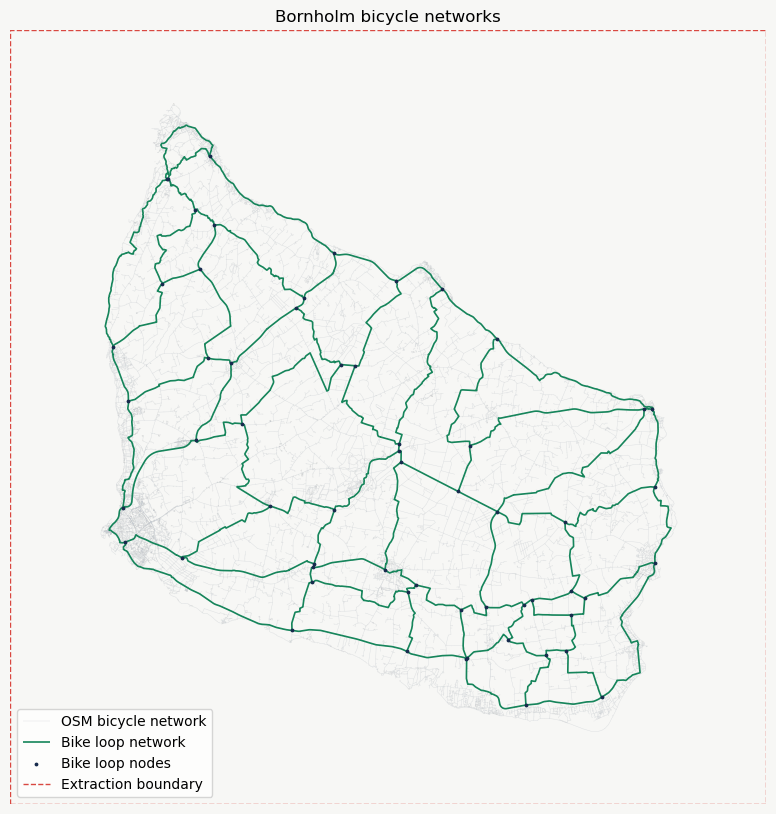

In [102]:
plot_bicycle_networks(
    sample=SAMPLE,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    bike_loops_bbox_gdf=bike_loops_bbox_gdf,
    osm_edges=osm_edges,
)

### Overlap analysis of the two bike networks

In [103]:
osm_spatial_index = osm_edges.sindex
matched_geometries, unmatched_geometries, matched_lengths, osm_candidate_counts = [], [], [], []

matched_osm_ids, matched_lit_values, matched_surface_values = [], [], []
number_of_edges = len(bike_loops_edges)

for position, geometry in enumerate(bike_loops_edges.geometry, start=1):

    # Find only OSM lines within the matching tolerance
    candidate_positions = osm_spatial_index.query(
        geometry,
        predicate="dwithin", # This predicate finds geometries that are within a specified distance of the input geometry.
        distance=TOLERANCE_M,
    )

    candidate_positions = np.unique(candidate_positions)
    
    candidates = osm_edges.iloc[candidate_positions]

    if candidates.empty:
        matched_geometry = shapely.GeometryCollection()
        unmatched_geometry = geometry

        matched_osm_id = np.nan
        lit_value = np.nan
        surface_value = np.nan

    else:
        # Calculate the complete matched geometry
        local_osm_network = shapely.union_all(candidates.geometry.array)
        local_osm_buffer = local_osm_network.buffer(TOLERANCE_M)
        matched_geometry = geometry.intersection(local_osm_buffer)
        unmatched_geometry = geometry.difference(local_osm_buffer)
        
        # Find which candidate covers the greatest
        # length of this bike-loop edge
        candidate_buffers = (
            candidates.geometry.buffer(
                TOLERANCE_M
            )
        )

        candidate_overlap_lengths = (
            candidate_buffers
            .intersection(geometry)
            .length
        )

        best_position = (
            candidate_overlap_lengths
            .to_numpy()
            .argmax()
        )

        best_candidate = candidates.iloc[best_position]

        matched_osm_id = best_candidate.get("id", np.nan)
        lit_value = best_candidate.get("lit", np.nan)
        surface_value = best_candidate.get("surface", np.nan)

    matched_geometries.append(matched_geometry)
    unmatched_geometries.append(unmatched_geometry)
    matched_lengths.append(matched_geometry.length)
    osm_candidate_counts.append(len(candidates))
    matched_osm_ids.append(matched_osm_id)
    matched_lit_values.append(lit_value)
    matched_surface_values.append(surface_value)

    if position % 500 == 0:
        print(f"Processed {position:,} of {number_of_edges:,} bike-loop edges")

print("Matching completed.")

Matching completed.


In [104]:
bike_loops_overlap = bike_loops_edges.copy()
bike_loops_overlap["bike_loop_length_m"] = (bike_loops_overlap.geometry.length)
bike_loops_overlap["matched_length_m"] = (matched_lengths)
bike_loops_overlap["unmatched_length_m"] = (bike_loops_overlap["bike_loop_length_m"] - bike_loops_overlap["matched_length_m"])
bike_loops_overlap["coverage_pct"] = (100 * bike_loops_overlap["matched_length_m"] / bike_loops_overlap["bike_loop_length_m"])
bike_loops_overlap["osm_candidate_count"] = (osm_candidate_counts)
bike_loops_overlap["matched_osm_id"] = (matched_osm_ids)
bike_loops_overlap["lit"] = (matched_lit_values)
bike_loops_overlap["surface"] = (matched_surface_values)

bike_loops_overlap["lit_group"] = (
    bike_loops_overlap["lit"].apply(
        group_lit
    )
)

bike_loops_overlap["surface_group"] = (
    bike_loops_overlap["surface"].apply(
        group_surface
    )
)

result_columns = [
    column
    for column in [
        "edge_id",
        "node_start",
        "node_end",
        "bike_loop_length_m",
        "matched_length_m",
        "unmatched_length_m",
        "coverage_pct",
        "osm_candidate_count",
        "matched_osm_id",
        "lit",
        "lit_group",
        "surface",
        "surface_group",
    ]
    if column in bike_loops_overlap.columns
]

matched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=matched_geometries,
    crs=BIKE_LOOPS_CRS,
)

unmatched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=unmatched_geometries,
    crs=BIKE_LOOPS_CRS,
)

matched_edges = matched_edges.loc[~matched_edges.geometry.is_empty].copy()
unmatched_edges = unmatched_edges.loc[~unmatched_edges.geometry.is_empty].copy()

print(f"Matched edges: {len(matched_edges):,}")
print(f"Edges with unmatched geometry: {len(unmatched_edges):,}")

Matched edges: 89
Edges with unmatched geometry: 5


Bike-loop length: 375.73 km
Matched length: 374.81 km
Unmatched length: 0.92 km
Coverage: 99.76%


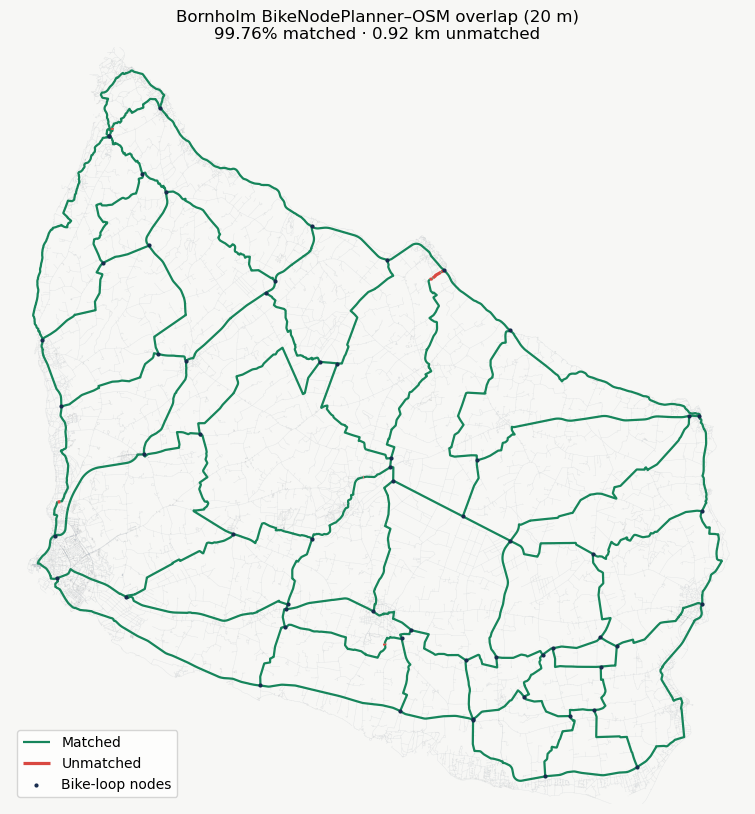

In [105]:
overlap_summary = plot_overlap_results(
    sample=SAMPLE,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    osm_edges=osm_edges,
    bike_loops_overlap=bike_loops_overlap,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
)

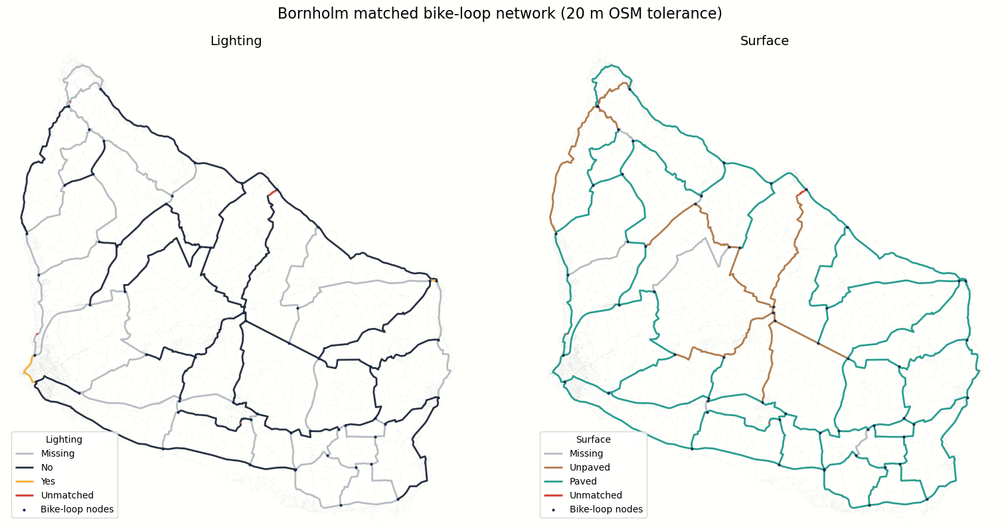

Saved: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/bornholm/bornholm_matched_lit_surface.png


In [106]:
fig, axes = plot_matched_attribute(
    sample=SAMPLE,
    osm_edges=osm_edges,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
)

## Fyn

In [107]:
SAMPLE = "funen"

BIKE_LOOPS_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"
OUTPUT_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}"

OSM_EDGES_PATH = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_osm_bike_edges.parquet"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OSM_EDGES_PATH.parent.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Bike loop network directory:", BIKE_LOOPS_DIR)
print("Output folder:", OUTPUT_DIR)

Project root: /Users/ellenebdrup/Documents/GitHub/bike_safety
Bike loop network directory: /Users/ellenebdrup/Documents/GitHub/bike_safety/bikenwloops/data/input/funen/network/processed
Output folder: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/funen


In [108]:
# Load bike loop network data
bike_loops_edges = gpd.read_file(BIKE_LOOPS_DIR / "edges_slope.gpkg")
bike_loops_nodes = gpd.read_file(BIKE_LOOPS_DIR / "nodes.gpkg")

bike_loops_edges = bike_loops_edges.loc[
    bike_loops_edges.geometry.notna()
    & ~bike_loops_edges.geometry.is_empty
].copy()

bike_loops_nodes = bike_loops_nodes.loc[
    bike_loops_nodes.geometry.notna()
    & ~bike_loops_nodes.geometry.is_empty
].copy()

if bike_loops_edges.crs is None:
    raise ValueError("The bike-loop edges do not have a CRS.")

BIKE_LOOPS_CRS = bike_loops_edges.crs
bike_loops_nodes = bike_loops_nodes.to_crs(BIKE_LOOPS_CRS)

print("Bike loops CRS:", BIKE_LOOPS_CRS)
print(f"Bike loop edges: {len(bike_loops_edges):,}")
print(f"Bike loop nodes: {len(bike_loops_nodes):,}")

Bike loops CRS: EPSG:25832
Bike loop edges: 1,438
Bike loop nodes: 1,014


In [109]:
minx, miny, maxx, maxy = bike_loops_edges.total_bounds

bike_loops_bbox = box(
    minx - EXTRACTION_MARGIN_M,
    miny - EXTRACTION_MARGIN_M,
    maxx + EXTRACTION_MARGIN_M,
    maxy + EXTRACTION_MARGIN_M,
)

# The bounding box below uses the BikeNodePlanner coordinate system (Bike loops CRS: EPSG:25832) with coordinates measured in metres. 
# This is useful for applying the 5,000-metre margin and performing the 20-metre overlap analysis.
bike_loops_bbox_gdf = gpd.GeoDataFrame(
    geometry=[bike_loops_bbox],
    crs=BIKE_LOOPS_CRS,
)

# WGS84 means the bounding box coordinates have been converted to the standard global longitude/latitude coordinate system, EPSG:4326.
bike_loops_bbox_wgs84 = (
    bike_loops_bbox_gdf
    .to_crs("EPSG:4326")
    .geometry
    .iloc[0]
)

### Extract area of interest from OSM data

In [110]:
required_osm_columns = {
    "geometry",
    "lit",
    "surface",
}

rebuild_osm_cache = True

### Time: ≈ 8 min
if OSM_EDGES_PATH.exists():
    osm_edges = gpd.read_parquet(OSM_EDGES_PATH)

    missing_columns = (required_osm_columns - set(osm_edges.columns))

    if not missing_columns:
        rebuild_osm_cache = False
        print(f"Loaded cached {SAMPLE} OSM bicycle network.")

    else:
        print(f"The cached file is missing: {sorted(missing_columns)}")
        print("Rebuilding the OSM cache...")

if rebuild_osm_cache:
    print(f"Extracting the {SAMPLE} bicycle network from the Denmark PBF...")

    osm_reader = OSM(str(PBF_PATH), bounding_box=bike_loops_bbox_wgs84)

    osm_edges = osm_reader.get_network(
        network_type="cycling",
        extra_attributes=["lit", "surface"],
    )

    osm_edges = osm_edges.loc[
        osm_edges.geometry.notna()
        & ~osm_edges.geometry.is_empty
    ].copy()

    osm_edges = osm_edges.explode(
        index_parts=False,
        ignore_index=True,
    )

    osm_edges = osm_edges.to_crs(BIKE_LOOPS_CRS)

    columns_to_keep = [
        column
        for column in [
            "id",
            "name",
            "highway",
            "lit",
            "surface",
            "geometry",
        ]
        if column in osm_edges.columns
    ]

    osm_edges = osm_edges[columns_to_keep].copy()
    osm_edges.to_parquet(OSM_EDGES_PATH)
    print(f"Saved {SAMPLE.title()} OSM bicycle network.")

print(f"OSM bicycle edges: {len(osm_edges):,}")
print("OSM CRS:", osm_edges.crs)

Loaded cached funen OSM bicycle network.
OSM bicycle edges: 719,553
OSM CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "ETRS89 / UTM zone 32N", "base_crs": {"type": "GeographicCRS", "name": "ETRS89", "datum_ensemble": {"name": "European Terrestrial Reference System 1989 ensemble", "members": [{"name": "European Terrestrial Reference Frame 1989"}, {"name": "European Terrestrial Reference Frame 1990"}, {"name": "European Terrestrial Reference Frame 1991"}, {"name": "European Terrestrial Reference Frame 1992"}, {"name": "European Terrestrial Reference Frame 1993"}, {"name": "European Terrestrial Reference Frame 1994"}, {"name": "European Terrestrial Reference Frame 1996"}, {"name": "European Terrestrial Reference Frame 1997"}, {"name": "European Terrestrial Reference Frame 2000"}, {"name": "European Terrestrial Reference Frame 2005"}, {"name": "European Terrestrial Reference Frame 2014"}, {"name": "European Terrestrial Reference Fram

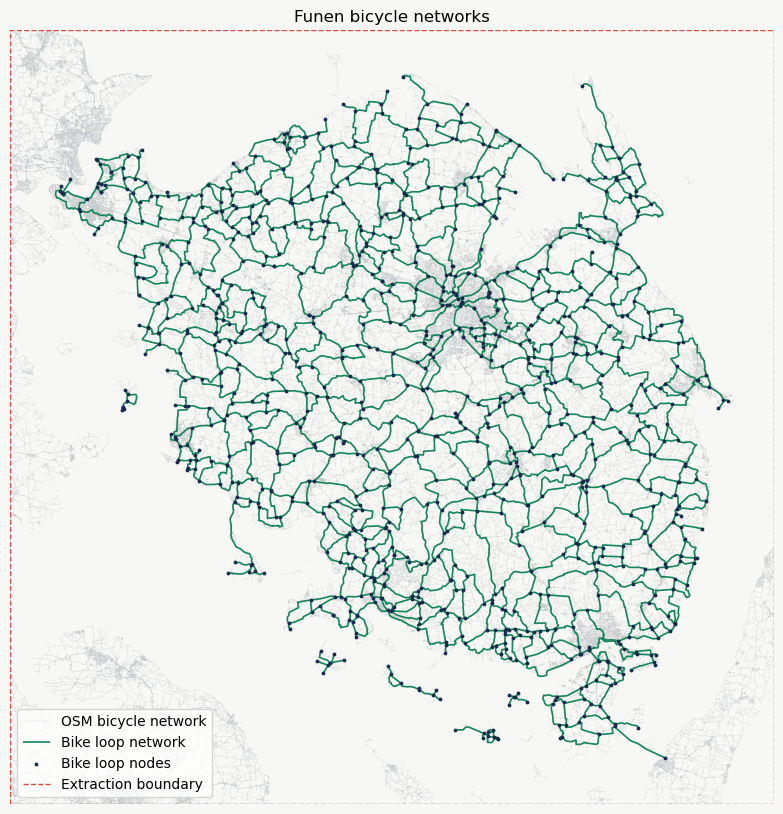

In [111]:
plot_bicycle_networks(
    sample=SAMPLE,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    bike_loops_bbox_gdf=bike_loops_bbox_gdf,
    osm_edges=osm_edges,
)

### Overlap analysis of the two bike networks

In [112]:
osm_spatial_index = osm_edges.sindex
matched_geometries, unmatched_geometries, matched_lengths, osm_candidate_counts = [], [], [], []

matched_osm_ids, matched_lit_values, matched_surface_values = [], [], []

number_of_edges = len(bike_loops_edges)

for position, geometry in enumerate(bike_loops_edges.geometry, start=1):

    # Find only OSM lines within the matching tolerance
    candidate_positions = osm_spatial_index.query(
        geometry,
        predicate="dwithin", # This predicate finds geometries that are within a specified distance of the input geometry.
        distance=TOLERANCE_M,
    )

    candidate_positions = np.unique(candidate_positions)
    candidates = osm_edges.iloc[candidate_positions]

    if candidates.empty:
        matched_geometry = shapely.GeometryCollection()
        unmatched_geometry = geometry

        matched_osm_id = np.nan
        lit_value = np.nan
        surface_value = np.nan

    else:
        # Calculate the complete matched geometry
        local_osm_network = shapely.union_all(candidates.geometry.array)
        local_osm_buffer = local_osm_network.buffer(TOLERANCE_M)
        matched_geometry = geometry.intersection(local_osm_buffer)
        unmatched_geometry = geometry.difference(local_osm_buffer)
        
        # Find which candidate covers the greatest
        # length of this bike-loop edge
        candidate_buffers = (
            candidates.geometry.buffer(
                TOLERANCE_M
            )
        )

        candidate_overlap_lengths = (
            candidate_buffers
            .intersection(geometry)
            .length
        )

        best_position = (
            candidate_overlap_lengths
            .to_numpy()
            .argmax()
        )

        best_candidate = candidates.iloc[best_position]

        matched_osm_id = best_candidate.get("id", np.nan)
        lit_value = best_candidate.get("lit", np.nan)
        surface_value = best_candidate.get("surface", np.nan)

    matched_geometries.append(matched_geometry)
    unmatched_geometries.append(unmatched_geometry)
    matched_lengths.append(matched_geometry.length)
    osm_candidate_counts.append(len(candidates))
    matched_osm_ids.append(matched_osm_id)
    matched_lit_values.append(lit_value)
    matched_surface_values.append(surface_value)

    if position % 500 == 0:
        print(f"Processed {position:,} of {number_of_edges:,} bike-loop edges")

print("Matching completed.")

Processed 500 of 1,438 bike-loop edges
Processed 1,000 of 1,438 bike-loop edges
Matching completed.


In [113]:
bike_loops_overlap = bike_loops_edges.copy()
bike_loops_overlap["bike_loop_length_m"] = (bike_loops_overlap.geometry.length)
bike_loops_overlap["matched_length_m"] = (matched_lengths)
bike_loops_overlap["unmatched_length_m"] = (bike_loops_overlap["bike_loop_length_m"] - bike_loops_overlap["matched_length_m"])
bike_loops_overlap["coverage_pct"] = (100 * bike_loops_overlap["matched_length_m"] / bike_loops_overlap["bike_loop_length_m"])
bike_loops_overlap["osm_candidate_count"] = (osm_candidate_counts)
bike_loops_overlap["matched_osm_id"] = (matched_osm_ids)
bike_loops_overlap["lit"] = (matched_lit_values)
bike_loops_overlap["surface"] = (matched_surface_values)

bike_loops_overlap["lit_group"] = (
    bike_loops_overlap["lit"].apply(
        group_lit
    )
)

bike_loops_overlap["surface_group"] = (
    bike_loops_overlap["surface"].apply(
        group_surface
    )
)

result_columns = [
    column
    for column in [
        "edge_id",
        "node_start",
        "node_end",
        "bike_loop_length_m",
        "matched_length_m",
        "unmatched_length_m",
        "coverage_pct",
        "osm_candidate_count",
        "matched_osm_id",
        "lit",
        "lit_group",
        "surface",
        "surface_group",
    ]
    if column in bike_loops_overlap.columns
]

matched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=matched_geometries,
    crs=BIKE_LOOPS_CRS,
)

unmatched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=unmatched_geometries,
    crs=BIKE_LOOPS_CRS,
)

matched_edges = matched_edges.loc[~matched_edges.geometry.is_empty].copy()
unmatched_edges = unmatched_edges.loc[~unmatched_edges.geometry.is_empty].copy()

print(f"Matched edges: {len(matched_edges):,}")
print(f"Edges with unmatched geometry: {len(unmatched_edges):,}")

Matched edges: 1,436
Edges with unmatched geometry: 120


Bike-loop length: 2,753.85 km
Matched length: 2,726.18 km
Unmatched length: 27.67 km
Coverage: 99.00%


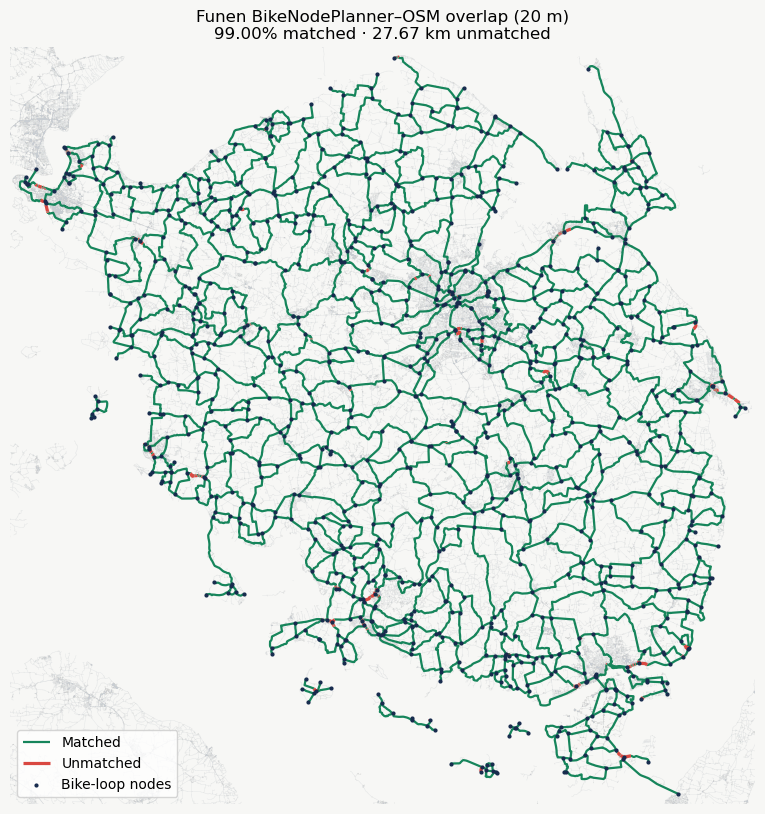

In [114]:
overlap_summary = plot_overlap_results(
    sample=SAMPLE,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    osm_edges=osm_edges,
    bike_loops_overlap=bike_loops_overlap,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
)

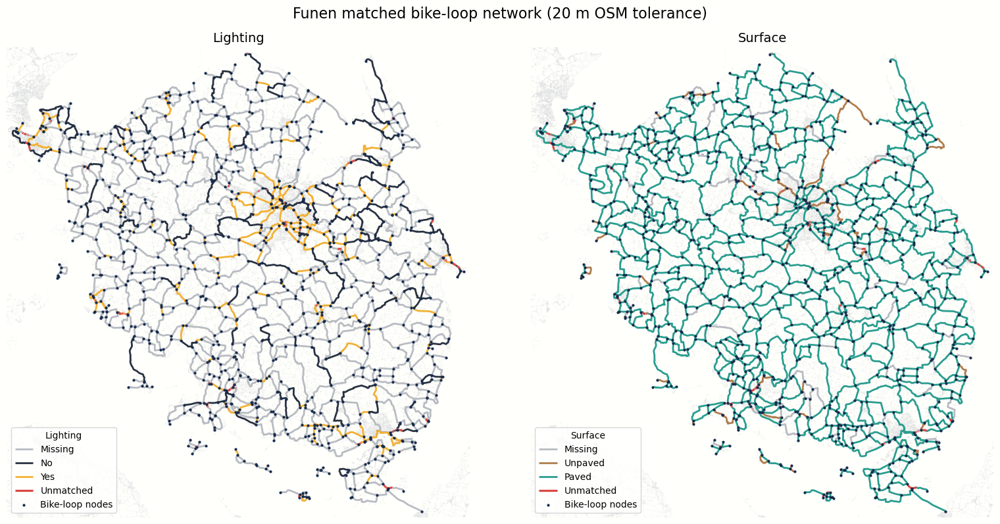

Saved: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/funen/funen_matched_lit_surface.png


In [115]:
fig, axes = plot_matched_attribute(
    sample=SAMPLE,
    osm_edges=osm_edges,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
)

## Jylland

In [116]:
SAMPLE = "jutland"

BIKE_LOOPS_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"
OUTPUT_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}"

OSM_EDGES_PATH = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_osm_bike_edges.parquet"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OSM_EDGES_PATH.parent.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Bike loop network directory:", BIKE_LOOPS_DIR)
print("Output folder:", OUTPUT_DIR)

Project root: /Users/ellenebdrup/Documents/GitHub/bike_safety
Bike loop network directory: /Users/ellenebdrup/Documents/GitHub/bike_safety/bikenwloops/data/input/jutland/network/processed
Output folder: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/jutland


In [117]:
# Load bike loop network data
bike_loops_edges = gpd.read_file(BIKE_LOOPS_DIR / "edges_slope.gpkg")
bike_loops_nodes = gpd.read_file(BIKE_LOOPS_DIR / "nodes.gpkg")

bike_loops_edges = bike_loops_edges.loc[
    bike_loops_edges.geometry.notna()
    & ~bike_loops_edges.geometry.is_empty
].copy()

bike_loops_nodes = bike_loops_nodes.loc[
    bike_loops_nodes.geometry.notna()
    & ~bike_loops_nodes.geometry.is_empty
].copy()

if bike_loops_edges.crs is None:
    raise ValueError("The bike-loop edges do not have a CRS.")

BIKE_LOOPS_CRS = bike_loops_edges.crs
bike_loops_nodes = bike_loops_nodes.to_crs(BIKE_LOOPS_CRS)

print("Bike loops CRS:", BIKE_LOOPS_CRS)
print(f"Bike loop edges: {len(bike_loops_edges):,}")
print(f"Bike loop nodes: {len(bike_loops_nodes):,}")

Bike loops CRS: EPSG:25832
Bike loop edges: 7,253
Bike loop nodes: 5,006


In [118]:
minx, miny, maxx, maxy = bike_loops_edges.total_bounds

bike_loops_bbox = box(
    minx - EXTRACTION_MARGIN_M,
    miny - EXTRACTION_MARGIN_M,
    maxx + EXTRACTION_MARGIN_M,
    maxy + EXTRACTION_MARGIN_M,
)

# The bounding box below uses the BikeNodePlanner coordinate system (Bike loops CRS: EPSG:25832) with coordinates measured in metres. 
# This is useful for applying the 5,000-metre margin and performing the 20-metre overlap analysis.
bike_loops_bbox_gdf = gpd.GeoDataFrame(
    geometry=[bike_loops_bbox],
    crs=BIKE_LOOPS_CRS,
)

# WGS84 means the bounding box coordinates have been converted to the standard global longitude/latitude coordinate system, EPSG:4326.
bike_loops_bbox_wgs84 = (
    bike_loops_bbox_gdf
    .to_crs("EPSG:4326")
    .geometry
    .iloc[0]
)

### Extract area of interest from OSM data

In [119]:
required_osm_columns = {
    "geometry",
    "lit",
    "surface",
}

rebuild_osm_cache = True

### Time: ≈ 50 min
if OSM_EDGES_PATH.exists():
    osm_edges = gpd.read_parquet(OSM_EDGES_PATH)
    missing_columns = (required_osm_columns - set(osm_edges.columns))
    
    if not missing_columns:
        rebuild_osm_cache = False
        print(f"Loaded cached {SAMPLE} OSM bicycle network.")

    else:
        print(f"The cached file is missing: {sorted(missing_columns)}")
        print("Rebuilding the OSM cache...")

if rebuild_osm_cache:
    print(f"Extracting the {SAMPLE} bicycle network from the Denmark PBF...")

    osm_reader = OSM(str(PBF_PATH), bounding_box=bike_loops_bbox_wgs84)

    osm_edges = osm_reader.get_network(
        network_type="cycling",
        extra_attributes=["lit", "surface"],
    )

    osm_edges = osm_edges.loc[
        osm_edges.geometry.notna()
        & ~osm_edges.geometry.is_empty
    ].copy()

    osm_edges = osm_edges.explode(
        index_parts=False,
        ignore_index=True,
    )

    osm_edges = osm_edges.to_crs(BIKE_LOOPS_CRS)

    columns_to_keep = [
        column
        for column in [
            "id",
            "name",
            "highway",
            "lit",
            "surface",
            "geometry",
        ]
        if column in osm_edges.columns
    ]

    osm_edges = osm_edges[columns_to_keep].copy()
    osm_edges.to_parquet(OSM_EDGES_PATH)
    print(f"Saved {SAMPLE.title()} OSM bicycle network.")

print(f"OSM bicycle edges: {len(osm_edges):,}")
print("OSM CRS:", osm_edges.crs)

Loaded cached jutland OSM bicycle network.
OSM bicycle edges: 4,687,424
OSM CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "ETRS89 / UTM zone 32N", "base_crs": {"type": "GeographicCRS", "name": "ETRS89", "datum_ensemble": {"name": "European Terrestrial Reference System 1989 ensemble", "members": [{"name": "European Terrestrial Reference Frame 1989"}, {"name": "European Terrestrial Reference Frame 1990"}, {"name": "European Terrestrial Reference Frame 1991"}, {"name": "European Terrestrial Reference Frame 1992"}, {"name": "European Terrestrial Reference Frame 1993"}, {"name": "European Terrestrial Reference Frame 1994"}, {"name": "European Terrestrial Reference Frame 1996"}, {"name": "European Terrestrial Reference Frame 1997"}, {"name": "European Terrestrial Reference Frame 2000"}, {"name": "European Terrestrial Reference Frame 2005"}, {"name": "European Terrestrial Reference Frame 2014"}, {"name": "European Terrestrial Reference 

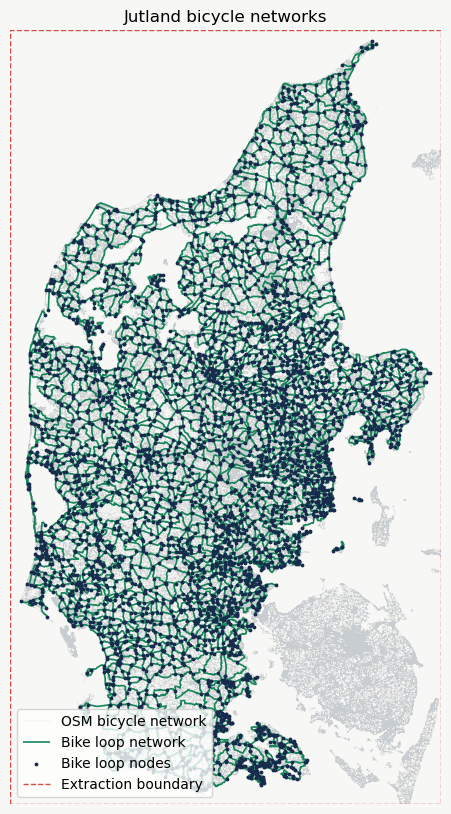

In [120]:
plot_bicycle_networks(
    sample=SAMPLE,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    bike_loops_bbox_gdf=bike_loops_bbox_gdf,
    osm_edges=osm_edges,
)

### Overlap analysis of the two bike networks

In [121]:
osm_spatial_index = osm_edges.sindex
matched_geometries, unmatched_geometries, matched_lengths, osm_candidate_counts = [], [], [], []

matched_osm_ids, matched_lit_values, matched_surface_values = [], [], []
number_of_edges = len(bike_loops_edges)

for position, geometry in enumerate(bike_loops_edges.geometry, start=1):

    # Find only OSM lines within the matching tolerance
    candidate_positions = osm_spatial_index.query(
        geometry,
        predicate="dwithin", # This predicate finds geometries that are within a specified distance of the input geometry.
        distance=TOLERANCE_M,
    )

    candidate_positions = np.unique(candidate_positions)
    
    candidates = osm_edges.iloc[candidate_positions]

    if candidates.empty:
        matched_geometry = shapely.GeometryCollection()
        unmatched_geometry = geometry

        matched_osm_id = np.nan
        lit_value = np.nan
        surface_value = np.nan

    else:
        # Calculate the complete matched geometry
        local_osm_network = shapely.union_all(candidates.geometry.array)
        local_osm_buffer = local_osm_network.buffer(TOLERANCE_M)
        matched_geometry = geometry.intersection(local_osm_buffer)
        unmatched_geometry = geometry.difference(local_osm_buffer)
        
        # Find which candidate covers the greatest
        # length of this bike-loop edge
        candidate_buffers = (
            candidates.geometry.buffer(
                TOLERANCE_M
            )
        )

        candidate_overlap_lengths = (
            candidate_buffers
            .intersection(geometry)
            .length
        )

        best_position = (
            candidate_overlap_lengths
            .to_numpy()
            .argmax()
        )

        best_candidate = candidates.iloc[best_position]

        matched_osm_id = best_candidate.get("id", np.nan)
        lit_value = best_candidate.get("lit", np.nan)
        surface_value = best_candidate.get("surface", np.nan)

    matched_geometries.append(matched_geometry)
    unmatched_geometries.append(unmatched_geometry)
    matched_lengths.append(matched_geometry.length)
    osm_candidate_counts.append(len(candidates))
    matched_osm_ids.append(matched_osm_id)
    matched_lit_values.append(lit_value)
    matched_surface_values.append(surface_value)

    if position % 500 == 0:
        print(f"Processed {position:,} of {number_of_edges:,} bike-loop edges")


Processed 500 of 7,253 bike-loop edges
Processed 1,000 of 7,253 bike-loop edges
Processed 1,500 of 7,253 bike-loop edges
Processed 2,000 of 7,253 bike-loop edges
Processed 2,500 of 7,253 bike-loop edges
Processed 3,000 of 7,253 bike-loop edges
Processed 3,500 of 7,253 bike-loop edges
Processed 4,000 of 7,253 bike-loop edges
Processed 4,500 of 7,253 bike-loop edges
Processed 5,000 of 7,253 bike-loop edges
Processed 5,500 of 7,253 bike-loop edges
Processed 6,000 of 7,253 bike-loop edges
Processed 6,500 of 7,253 bike-loop edges
Processed 7,000 of 7,253 bike-loop edges


In [122]:
bike_loops_overlap = bike_loops_edges.copy()
bike_loops_overlap["bike_loop_length_m"] = (bike_loops_overlap.geometry.length)
bike_loops_overlap["matched_length_m"] = (matched_lengths)
bike_loops_overlap["unmatched_length_m"] = (bike_loops_overlap["bike_loop_length_m"] - bike_loops_overlap["matched_length_m"])
bike_loops_overlap["coverage_pct"] = (100 * bike_loops_overlap["matched_length_m"] / bike_loops_overlap["bike_loop_length_m"])
bike_loops_overlap["osm_candidate_count"] = (osm_candidate_counts)

bike_loops_overlap["matched_osm_id"] = (matched_osm_ids)
bike_loops_overlap["lit"] = (matched_lit_values)
bike_loops_overlap["surface"] = (matched_surface_values)

bike_loops_overlap["lit_group"] = (
    bike_loops_overlap["lit"].apply(
        group_lit
    )
)

bike_loops_overlap["surface_group"] = (
    bike_loops_overlap["surface"].apply(
        group_surface
    )
)

result_columns = [
    column
    for column in [
        "edge_id",
        "node_start",
        "node_end",
        "bike_loop_length_m",
        "matched_length_m",
        "unmatched_length_m",
        "coverage_pct",
        "osm_candidate_count",
        "matched_osm_id",
        "lit",
        "lit_group",
        "surface",
        "surface_group",
    ]
    if column in bike_loops_overlap.columns
]

matched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=matched_geometries,
    crs=BIKE_LOOPS_CRS,
)

unmatched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=unmatched_geometries,
    crs=BIKE_LOOPS_CRS,
)

matched_edges = matched_edges.loc[~matched_edges.geometry.is_empty].copy()
unmatched_edges = unmatched_edges.loc[~unmatched_edges.geometry.is_empty].copy()

print(f"Matched edges: {len(matched_edges):,}")
print(f"Edges with unmatched geometry: {len(unmatched_edges):,}")

Matched edges: 7,249
Edges with unmatched geometry: 487


Bike-loop length: 18,950.86 km
Matched length: 18,853.13 km
Unmatched length: 97.74 km
Coverage: 99.48%


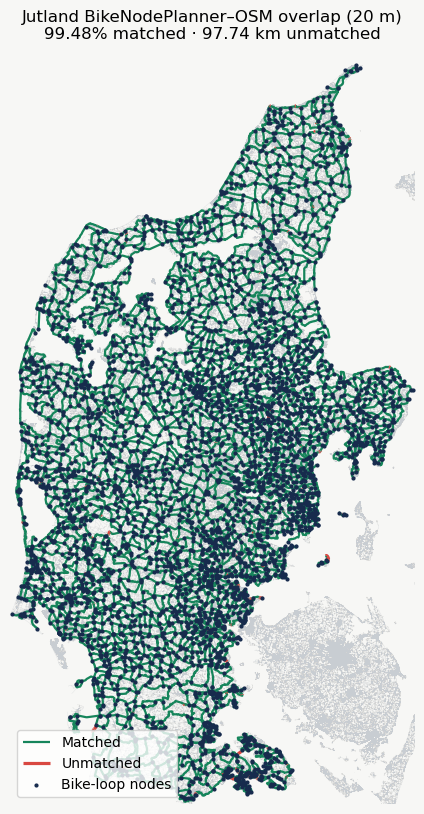

In [123]:
overlap_summary = plot_overlap_results(
    sample=SAMPLE,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    osm_edges=osm_edges,
    bike_loops_overlap=bike_loops_overlap,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
)

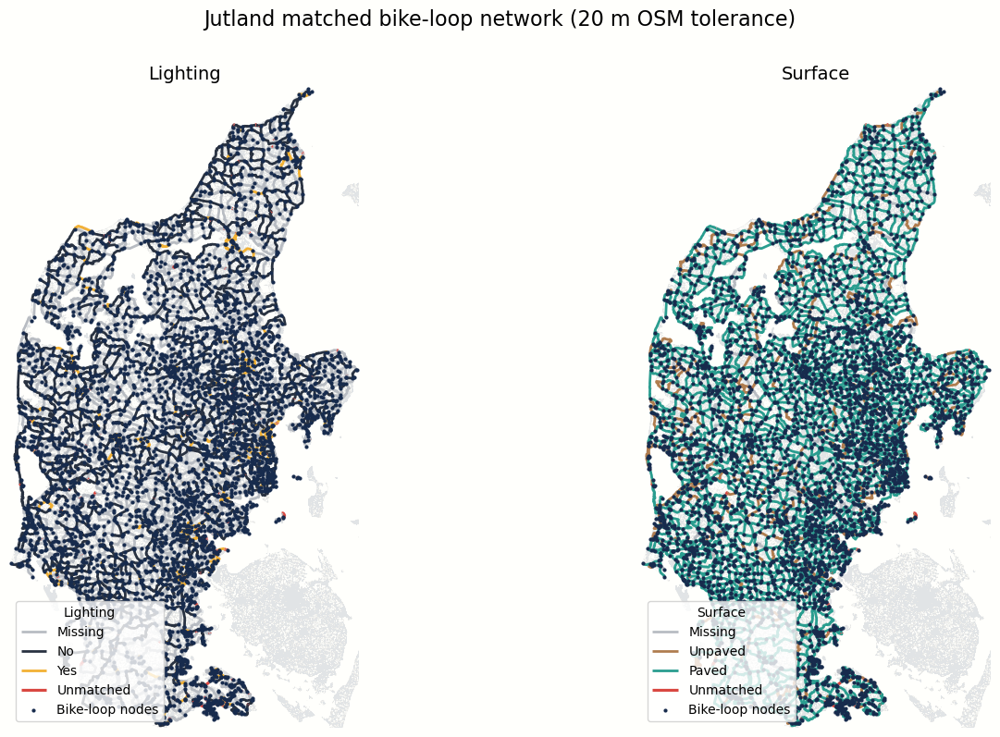

Saved: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/jutland/jutland_matched_lit_surface.png


In [124]:
fig, axes = plot_matched_attribute(
    sample=SAMPLE,
    osm_edges=osm_edges,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
)

## Lollandfalster

In [125]:
SAMPLE = "lollandfalster"

BIKE_LOOPS_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"
OUTPUT_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}"

OSM_EDGES_PATH = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_osm_bike_edges.parquet"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OSM_EDGES_PATH.parent.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Bike loop network directory:", BIKE_LOOPS_DIR)
print("Output folder:", OUTPUT_DIR)

Project root: /Users/ellenebdrup/Documents/GitHub/bike_safety
Bike loop network directory: /Users/ellenebdrup/Documents/GitHub/bike_safety/bikenwloops/data/input/lollandfalster/network/processed
Output folder: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/lollandfalster


In [126]:
# Load bike loop network data
bike_loops_edges = gpd.read_file(BIKE_LOOPS_DIR / "edges_slope.gpkg")
bike_loops_nodes = gpd.read_file(BIKE_LOOPS_DIR / "nodes.gpkg")

bike_loops_edges = bike_loops_edges.loc[
    bike_loops_edges.geometry.notna()
    & ~bike_loops_edges.geometry.is_empty
].copy()

bike_loops_nodes = bike_loops_nodes.loc[
    bike_loops_nodes.geometry.notna()
    & ~bike_loops_nodes.geometry.is_empty
].copy()

if bike_loops_edges.crs is None:
    raise ValueError("The bike-loop edges do not have a CRS.")

BIKE_LOOPS_CRS = bike_loops_edges.crs
bike_loops_nodes = bike_loops_nodes.to_crs(BIKE_LOOPS_CRS)

print("Bike loops CRS:", BIKE_LOOPS_CRS)
print(f"Bike loop edges: {len(bike_loops_edges):,}")
print(f"Bike loop nodes: {len(bike_loops_nodes):,}")

Bike loops CRS: EPSG:25832
Bike loop edges: 717
Bike loop nodes: 497


In [127]:
minx, miny, maxx, maxy = bike_loops_edges.total_bounds

bike_loops_bbox = box(
    minx - EXTRACTION_MARGIN_M,
    miny - EXTRACTION_MARGIN_M,
    maxx + EXTRACTION_MARGIN_M,
    maxy + EXTRACTION_MARGIN_M,
)

# The bounding box below uses the BikeNodePlanner coordinate system (Bike loops CRS: EPSG:25832) with coordinates measured in metres. 
# This is useful for applying the 5,000-metre margin and performing the 20-metre overlap analysis.
bike_loops_bbox_gdf = gpd.GeoDataFrame(
    geometry=[bike_loops_bbox],
    crs=BIKE_LOOPS_CRS,
)

# WGS84 means the bounding box coordinates have been converted to the standard global longitude/latitude coordinate system, EPSG:4326.
bike_loops_bbox_wgs84 = (
    bike_loops_bbox_gdf
    .to_crs("EPSG:4326")
    .geometry
    .iloc[0]
)

### Extract area of interest from OSM data

In [128]:
### Time: ≈ 2 min
required_osm_columns = {
    "geometry",
    "lit",
    "surface",
}

rebuild_osm_cache = True

if OSM_EDGES_PATH.exists():
    osm_edges = gpd.read_parquet(OSM_EDGES_PATH)
    missing_columns = (required_osm_columns - set(osm_edges.columns))
    
    if not missing_columns:
        rebuild_osm_cache = False
        print(f"Loaded cached {SAMPLE} OSM bicycle network.")

    else:
        print(f"The cached file is missing: {sorted(missing_columns)}")
        print("Rebuilding the OSM cache...")

if rebuild_osm_cache:
    print(f"Extracting the {SAMPLE} bicycle network from the Denmark PBF...")

    osm_reader = OSM(str(PBF_PATH), bounding_box=bike_loops_bbox_wgs84)

    osm_edges = osm_reader.get_network(
        network_type="cycling",
        extra_attributes=["lit", "surface"],
    )

    osm_edges = osm_edges.loc[
        osm_edges.geometry.notna()
        & ~osm_edges.geometry.is_empty
    ].copy()

    osm_edges = osm_edges.explode(
        index_parts=False,
        ignore_index=True,
    )

    osm_edges = osm_edges.to_crs(BIKE_LOOPS_CRS)

    columns_to_keep = [
        column
        for column in [
            "id",
            "name",
            "highway",
            "lit",
            "surface",
            "geometry",
        ]
        if column in osm_edges.columns
    ]

    osm_edges = osm_edges[columns_to_keep].copy()
    osm_edges.to_parquet(OSM_EDGES_PATH)
    print(f"Saved {SAMPLE.title()} OSM bicycle network.")

print(f"OSM bicycle edges: {len(osm_edges):,}")
print("OSM CRS:", osm_edges.crs)

Loaded cached lollandfalster OSM bicycle network.
OSM bicycle edges: 191,715
OSM CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "ETRS89 / UTM zone 32N", "base_crs": {"type": "GeographicCRS", "name": "ETRS89", "datum_ensemble": {"name": "European Terrestrial Reference System 1989 ensemble", "members": [{"name": "European Terrestrial Reference Frame 1989"}, {"name": "European Terrestrial Reference Frame 1990"}, {"name": "European Terrestrial Reference Frame 1991"}, {"name": "European Terrestrial Reference Frame 1992"}, {"name": "European Terrestrial Reference Frame 1993"}, {"name": "European Terrestrial Reference Frame 1994"}, {"name": "European Terrestrial Reference Frame 1996"}, {"name": "European Terrestrial Reference Frame 1997"}, {"name": "European Terrestrial Reference Frame 2000"}, {"name": "European Terrestrial Reference Frame 2005"}, {"name": "European Terrestrial Reference Frame 2014"}, {"name": "European Terrestrial Refer

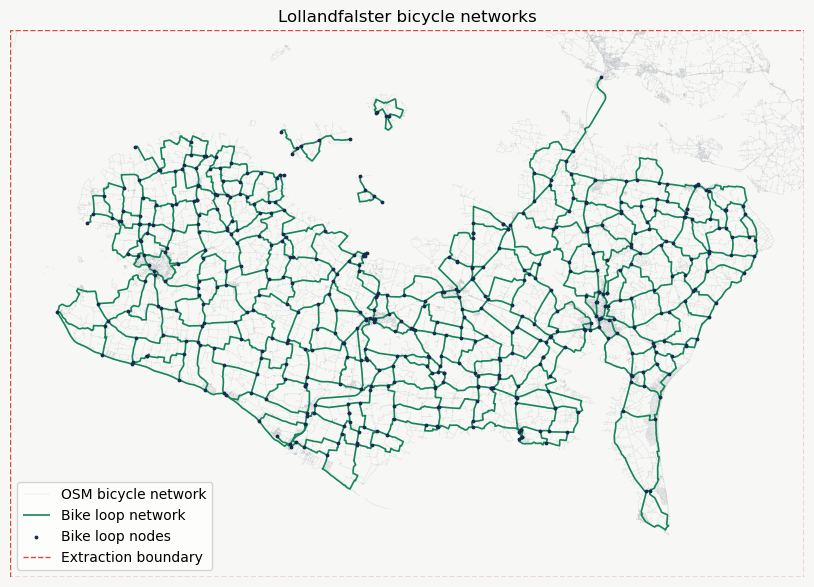

In [129]:
plot_bicycle_networks(
    sample=SAMPLE,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    bike_loops_bbox_gdf=bike_loops_bbox_gdf,
    osm_edges=osm_edges,
)

### Overlap analysis of the two bike networks

In [130]:
osm_spatial_index = osm_edges.sindex
matched_geometries, unmatched_geometries, matched_lengths, osm_candidate_counts = [], [], [], []

matched_osm_ids, matched_lit_values, matched_surface_values = [], [], []
number_of_edges = len(bike_loops_edges)

for position, geometry in enumerate(bike_loops_edges.geometry, start=1):

    # Find only OSM lines within the matching tolerance
    candidate_positions = osm_spatial_index.query(
        geometry,
        predicate="dwithin", # This predicate finds geometries that are within a specified distance of the input geometry.
        distance=TOLERANCE_M,
    )

    candidate_positions = np.unique(candidate_positions)
    
    candidates = osm_edges.iloc[candidate_positions]

    if candidates.empty:
        matched_geometry = shapely.GeometryCollection()
        unmatched_geometry = geometry

        matched_osm_id = np.nan
        lit_value = np.nan
        surface_value = np.nan

    else:
        # Calculate the complete matched geometry
        local_osm_network = shapely.union_all(candidates.geometry.array)
        local_osm_buffer = local_osm_network.buffer(TOLERANCE_M)
        matched_geometry = geometry.intersection(local_osm_buffer)
        unmatched_geometry = geometry.difference(local_osm_buffer)
        
        # Find which candidate covers the greatest
        # length of this bike-loop edge
        candidate_buffers = (
            candidates.geometry.buffer(
                TOLERANCE_M
            )
        )

        candidate_overlap_lengths = (
            candidate_buffers
            .intersection(geometry)
            .length
        )

        best_position = (
            candidate_overlap_lengths
            .to_numpy()
            .argmax()
        )

        best_candidate = candidates.iloc[best_position]

        matched_osm_id = best_candidate.get("id", np.nan)
        lit_value = best_candidate.get("lit", np.nan)
        surface_value = best_candidate.get("surface", np.nan)

    matched_geometries.append(matched_geometry)
    unmatched_geometries.append(unmatched_geometry)
    matched_lengths.append(matched_geometry.length)
    osm_candidate_counts.append(len(candidates))
    matched_osm_ids.append(matched_osm_id)
    matched_lit_values.append(lit_value)
    matched_surface_values.append(surface_value)

    if position % 500 == 0:
        print(f"Processed {position:,} of {number_of_edges:,} bike-loop edges")

print("Matching completed.")

Processed 500 of 717 bike-loop edges
Matching completed.


In [134]:
bike_loops_overlap = bike_loops_edges.copy()
bike_loops_overlap["bike_loop_length_m"] = (bike_loops_overlap.geometry.length)
bike_loops_overlap["matched_length_m"] = (matched_lengths)
bike_loops_overlap["unmatched_length_m"] = (bike_loops_overlap["bike_loop_length_m"] - bike_loops_overlap["matched_length_m"])
bike_loops_overlap["coverage_pct"] = (100 * bike_loops_overlap["matched_length_m"] / bike_loops_overlap["bike_loop_length_m"])
bike_loops_overlap["osm_candidate_count"] = (osm_candidate_counts)

bike_loops_overlap["matched_osm_id"] = (matched_osm_ids)
bike_loops_overlap["lit"] = (matched_lit_values)
bike_loops_overlap["surface"] = (matched_surface_values)

bike_loops_overlap["lit_group"] = (
    bike_loops_overlap["lit"].apply(
        group_lit
    )
)

bike_loops_overlap["surface_group"] = (
    bike_loops_overlap["surface"].apply(
        group_surface
    )
)

result_columns = [
    column
    for column in [
        "edge_id",
        "node_start",
        "node_end",
        "bike_loop_length_m",
        "matched_length_m",
        "unmatched_length_m",
        "coverage_pct",
        "osm_candidate_count",
        "matched_osm_id",
        "lit",
        "lit_group",
        "surface",
        "surface_group",
    ]
    if column in bike_loops_overlap.columns
]

matched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=matched_geometries,
    crs=BIKE_LOOPS_CRS,
)

unmatched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=unmatched_geometries,
    crs=BIKE_LOOPS_CRS,
)

matched_edges = matched_edges.loc[~matched_edges.geometry.is_empty].copy()
unmatched_edges = unmatched_edges.loc[~unmatched_edges.geometry.is_empty].copy()

print(f"Matched edges: {len(matched_edges):,}")
print(f"Edges with unmatched geometry: {len(unmatched_edges):,}")

Matched edges: 716
Edges with unmatched geometry: 62


Bike-loop length: 1,531.30 km
Matched length: 1,520.98 km
Unmatched length: 10.32 km
Coverage: 99.33%


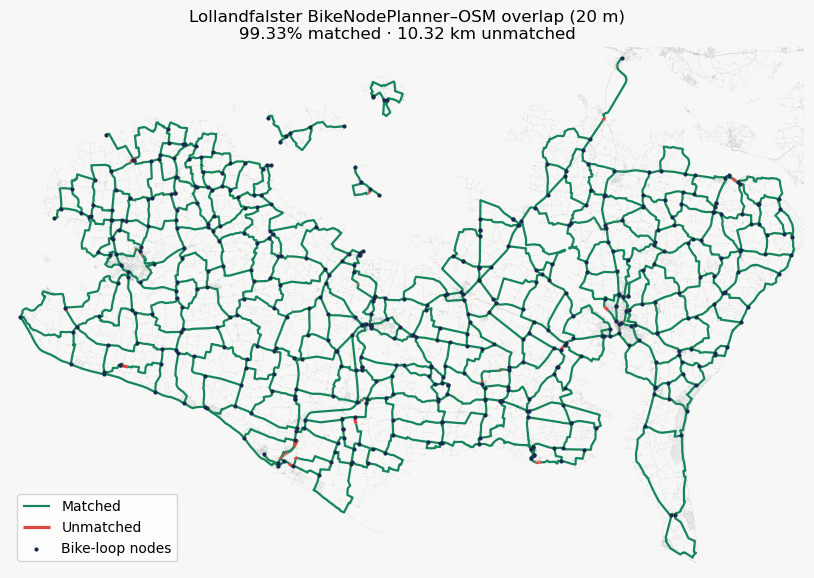

In [135]:
overlap_summary = plot_overlap_results(
    sample=SAMPLE,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    osm_edges=osm_edges,
    bike_loops_overlap=bike_loops_overlap,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
)

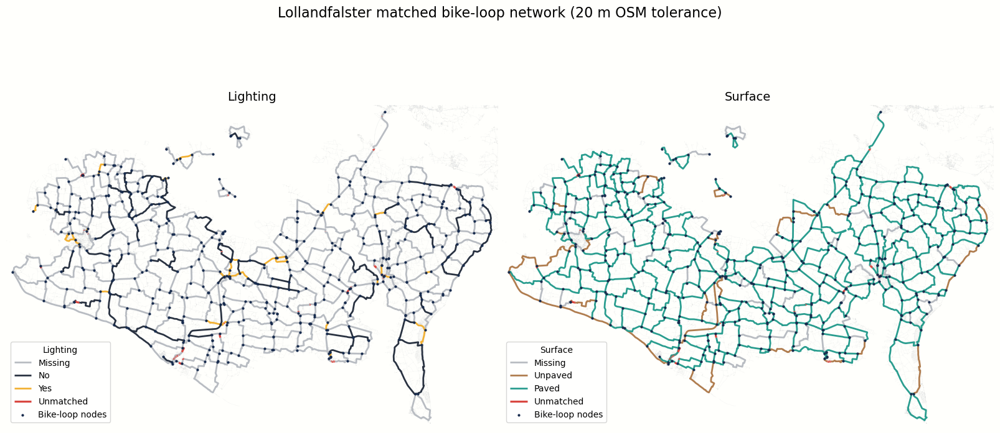

Saved: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/lollandfalster/lollandfalster_matched_lit_surface.png


In [136]:
fig, axes = plot_matched_attribute(
    sample=SAMPLE,
    osm_edges=osm_edges,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
)

## Langeland

In [137]:
SAMPLE = "longland"

BIKE_LOOPS_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"
OUTPUT_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}"

OSM_EDGES_PATH = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_osm_bike_edges.parquet"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OSM_EDGES_PATH.parent.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Bike loop network directory:", BIKE_LOOPS_DIR)
print("Output folder:", OUTPUT_DIR)

Project root: /Users/ellenebdrup/Documents/GitHub/bike_safety
Bike loop network directory: /Users/ellenebdrup/Documents/GitHub/bike_safety/bikenwloops/data/input/longland/network/processed
Output folder: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/longland


In [138]:
# Load bike loop network data
bike_loops_edges = gpd.read_file(BIKE_LOOPS_DIR / "edges_slope.gpkg")
bike_loops_nodes = gpd.read_file(BIKE_LOOPS_DIR / "nodes.gpkg")

bike_loops_edges = bike_loops_edges.loc[
    bike_loops_edges.geometry.notna()
    & ~bike_loops_edges.geometry.is_empty
].copy()

bike_loops_nodes = bike_loops_nodes.loc[
    bike_loops_nodes.geometry.notna()
    & ~bike_loops_nodes.geometry.is_empty
].copy()

if bike_loops_edges.crs is None:
    raise ValueError("The bike-loop edges do not have a CRS.")

BIKE_LOOPS_CRS = bike_loops_edges.crs
bike_loops_nodes = bike_loops_nodes.to_crs(BIKE_LOOPS_CRS)

print("Bike loops CRS:", BIKE_LOOPS_CRS)
print(f"Bike loop edges: {len(bike_loops_edges):,}")
print(f"Bike loop nodes: {len(bike_loops_nodes):,}")

Bike loops CRS: EPSG:25832
Bike loop edges: 130
Bike loop nodes: 102


In [139]:
minx, miny, maxx, maxy = bike_loops_edges.total_bounds

bike_loops_bbox = box(
    minx - EXTRACTION_MARGIN_M,
    miny - EXTRACTION_MARGIN_M,
    maxx + EXTRACTION_MARGIN_M,
    maxy + EXTRACTION_MARGIN_M,
)

# The bounding box below uses the BikeNodePlanner coordinate system (Bike loops CRS: EPSG:25832) with coordinates measured in metres. 
# This is useful for applying the 5,000-metre margin and performing the 20-metre overlap analysis.
bike_loops_bbox_gdf = gpd.GeoDataFrame(
    geometry=[bike_loops_bbox],
    crs=BIKE_LOOPS_CRS,
)

# WGS84 means the bounding box coordinates have been converted to the standard global longitude/latitude coordinate system, EPSG:4326.
bike_loops_bbox_wgs84 = (
    bike_loops_bbox_gdf
    .to_crs("EPSG:4326")
    .geometry
    .iloc[0]
)

### Extract area of interest from OSM data

In [140]:
### Time: ≈ 2-3 min
required_osm_columns = {
    "geometry",
    "lit",
    "surface",
}

rebuild_osm_cache = True

if OSM_EDGES_PATH.exists():
    osm_edges = gpd.read_parquet(OSM_EDGES_PATH)
    missing_columns = (required_osm_columns - set(osm_edges.columns))
    
    if not missing_columns:
        rebuild_osm_cache = False
        print(f"Loaded cached {SAMPLE} OSM bicycle network.")

    else:
        print(f"The cached file is missing: {sorted(missing_columns)}")
        print("Rebuilding the OSM cache...")

if rebuild_osm_cache:
    print(f"Extracting the {SAMPLE} bicycle network from the Denmark PBF...")

    osm_reader = OSM(str(PBF_PATH), bounding_box=bike_loops_bbox_wgs84)

    osm_edges = osm_reader.get_network(
        network_type="cycling",
        extra_attributes=["lit", "surface"],
    )

    osm_edges = osm_edges.loc[
        osm_edges.geometry.notna()
        & ~osm_edges.geometry.is_empty
    ].copy()

    osm_edges = osm_edges.explode(
        index_parts=False,
        ignore_index=True,
    )

    osm_edges = osm_edges.to_crs(BIKE_LOOPS_CRS)

    columns_to_keep = [
        column
        for column in [
            "id",
            "name",
            "highway",
            "lit",
            "surface",
            "geometry",
        ]
        if column in osm_edges.columns
    ]

    osm_edges = osm_edges[columns_to_keep].copy()
    osm_edges.to_parquet(OSM_EDGES_PATH)
    print(f"Saved {SAMPLE.title()} OSM bicycle network.")

print(f"OSM bicycle edges: {len(osm_edges):,}")
print("OSM CRS:", osm_edges.crs)

Loaded cached longland OSM bicycle network.
OSM bicycle edges: 110,367
OSM CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "ETRS89 / UTM zone 32N", "base_crs": {"type": "GeographicCRS", "name": "ETRS89", "datum_ensemble": {"name": "European Terrestrial Reference System 1989 ensemble", "members": [{"name": "European Terrestrial Reference Frame 1989"}, {"name": "European Terrestrial Reference Frame 1990"}, {"name": "European Terrestrial Reference Frame 1991"}, {"name": "European Terrestrial Reference Frame 1992"}, {"name": "European Terrestrial Reference Frame 1993"}, {"name": "European Terrestrial Reference Frame 1994"}, {"name": "European Terrestrial Reference Frame 1996"}, {"name": "European Terrestrial Reference Frame 1997"}, {"name": "European Terrestrial Reference Frame 2000"}, {"name": "European Terrestrial Reference Frame 2005"}, {"name": "European Terrestrial Reference Frame 2014"}, {"name": "European Terrestrial Reference F

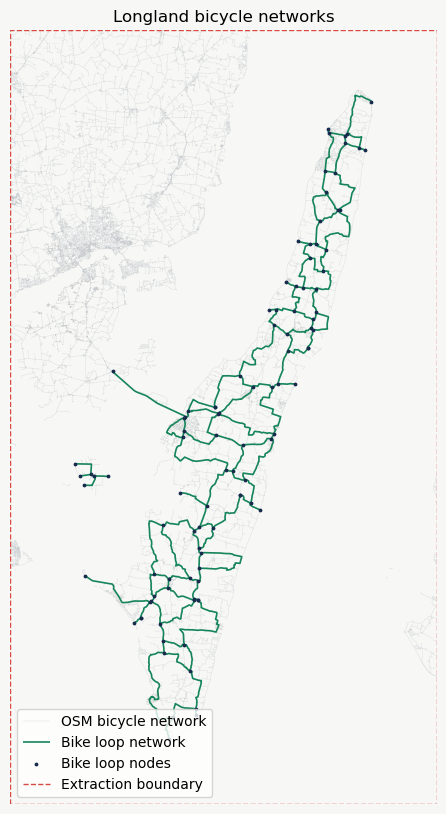

In [141]:
plot_bicycle_networks(
    sample=SAMPLE,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    bike_loops_bbox_gdf=bike_loops_bbox_gdf,
    osm_edges=osm_edges,
)

### Overlap analysis of the two bike networks

In [142]:
osm_spatial_index = osm_edges.sindex
matched_geometries, unmatched_geometries, matched_lengths, osm_candidate_counts = [], [], [], []

matched_osm_ids, matched_lit_values, matched_surface_values = [], [], []
number_of_edges = len(bike_loops_edges)

for position, geometry in enumerate(bike_loops_edges.geometry, start=1):

    # Find only OSM lines within the matching tolerance
    candidate_positions = osm_spatial_index.query(
        geometry,
        predicate="dwithin", # This predicate finds geometries that are within a specified distance of the input geometry.
        distance=TOLERANCE_M,
    )

    candidate_positions = np.unique(candidate_positions)
    
    candidates = osm_edges.iloc[candidate_positions]

    if candidates.empty:
        matched_geometry = shapely.GeometryCollection()
        unmatched_geometry = geometry

        matched_osm_id = np.nan
        lit_value = np.nan
        surface_value = np.nan

    else:
        # Calculate the complete matched geometry
        local_osm_network = shapely.union_all(candidates.geometry.array)
        local_osm_buffer = local_osm_network.buffer(TOLERANCE_M)
        matched_geometry = geometry.intersection(local_osm_buffer)
        unmatched_geometry = geometry.difference(local_osm_buffer)
        
        # Find which candidate covers the greatest
        # length of this bike-loop edge
        candidate_buffers = (
            candidates.geometry.buffer(
                TOLERANCE_M
            )
        )

        candidate_overlap_lengths = (
            candidate_buffers
            .intersection(geometry)
            .length
        )

        best_position = (
            candidate_overlap_lengths
            .to_numpy()
            .argmax()
        )

        best_candidate = candidates.iloc[best_position]

        matched_osm_id = best_candidate.get("id", np.nan)
        lit_value = best_candidate.get("lit", np.nan)
        surface_value = best_candidate.get("surface", np.nan)

    matched_geometries.append(matched_geometry)
    unmatched_geometries.append(unmatched_geometry)
    matched_lengths.append(matched_geometry.length)
    osm_candidate_counts.append(len(candidates))
    matched_osm_ids.append(matched_osm_id)
    matched_lit_values.append(lit_value)
    matched_surface_values.append(surface_value)

    if position % 500 == 0:
        print(f"Processed {position:,} of {number_of_edges:,} bike-loop edges")

print("Matching completed.")

Matching completed.


In [146]:
bike_loops_overlap = bike_loops_edges.copy()
bike_loops_overlap["bike_loop_length_m"] = (bike_loops_overlap.geometry.length)
bike_loops_overlap["matched_length_m"] = (matched_lengths)
bike_loops_overlap["unmatched_length_m"] = (bike_loops_overlap["bike_loop_length_m"] - bike_loops_overlap["matched_length_m"])
bike_loops_overlap["coverage_pct"] = (100 * bike_loops_overlap["matched_length_m"] / bike_loops_overlap["bike_loop_length_m"])
bike_loops_overlap["osm_candidate_count"] = (osm_candidate_counts)

bike_loops_overlap["matched_osm_id"] = (matched_osm_ids)
bike_loops_overlap["lit"] = (matched_lit_values)
bike_loops_overlap["surface"] = (matched_surface_values)

bike_loops_overlap["lit_group"] = (
    bike_loops_overlap["lit"].apply(
        group_lit
    )
)

bike_loops_overlap["surface_group"] = (
    bike_loops_overlap["surface"].apply(
        group_surface
    )
)

result_columns = [
    column
    for column in [
        "edge_id",
        "node_start",
        "node_end",
        "bike_loop_length_m",
        "matched_length_m",
        "unmatched_length_m",
        "coverage_pct",
        "osm_candidate_count",
        "matched_osm_id",
        "lit",
        "lit_group",
        "surface",
        "surface_group",
    ]
    if column in bike_loops_overlap.columns
]

matched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=matched_geometries,
    crs=BIKE_LOOPS_CRS,
)

unmatched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=unmatched_geometries,
    crs=BIKE_LOOPS_CRS,
)

matched_edges = matched_edges.loc[~matched_edges.geometry.is_empty].copy()
unmatched_edges = unmatched_edges.loc[~unmatched_edges.geometry.is_empty].copy()

print(f"Matched edges: {len(matched_edges):,}")
print(f"Edges with unmatched geometry: {len(unmatched_edges):,}")

Matched edges: 130
Edges with unmatched geometry: 7


Bike-loop length: 269.35 km
Matched length: 269.05 km
Unmatched length: 0.30 km
Coverage: 99.89%


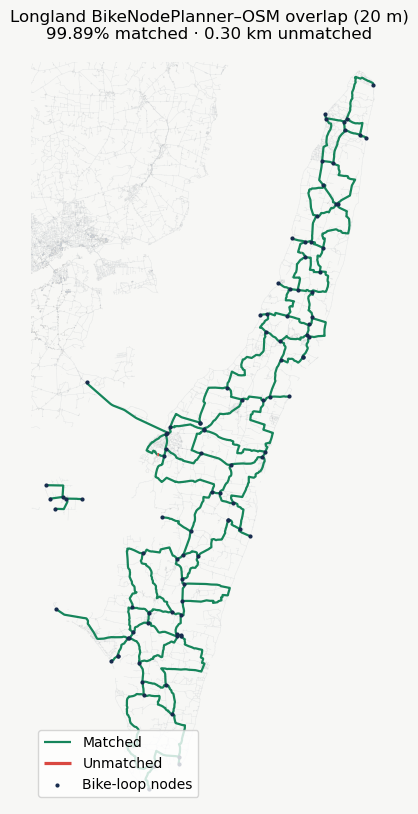

In [147]:
overlap_summary = plot_overlap_results(
    sample=SAMPLE,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    osm_edges=osm_edges,
    bike_loops_overlap=bike_loops_overlap,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
)

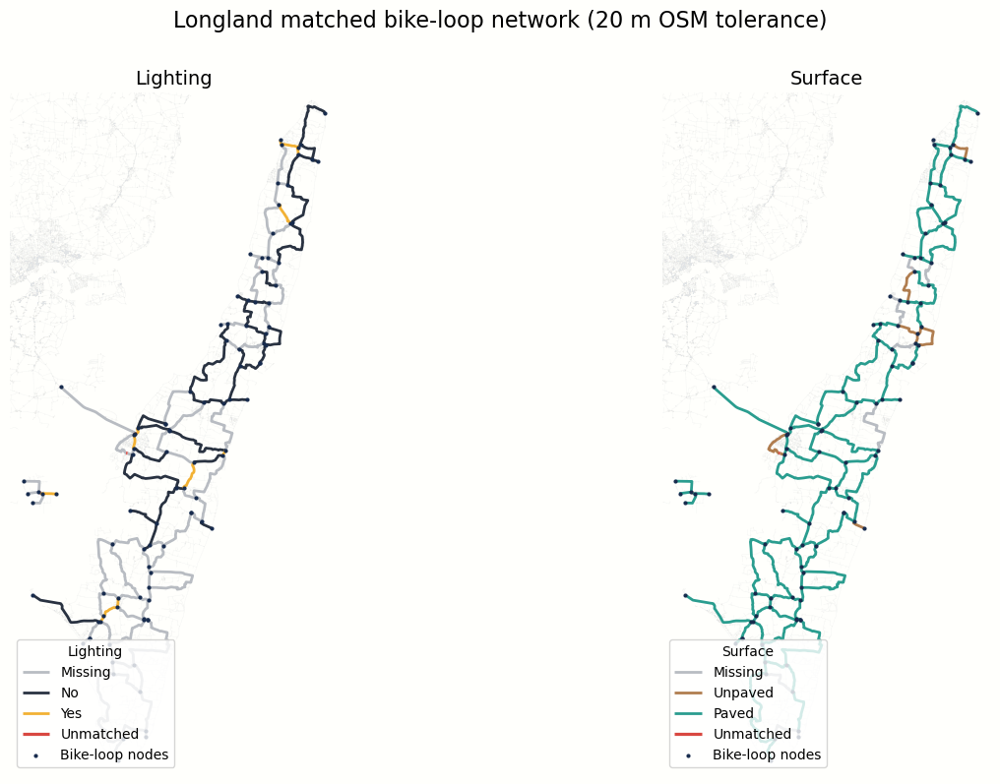

Saved: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/longland/longland_matched_lit_surface.png


In [148]:
fig, axes = plot_matched_attribute(
    sample=SAMPLE,
    osm_edges=osm_edges,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
)

## Sjælland

In [149]:
SAMPLE = "zealand"

BIKE_LOOPS_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"
OUTPUT_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}"

OSM_EDGES_PATH = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_osm_bike_edges.parquet"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OSM_EDGES_PATH.parent.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Bike loop network directory:", BIKE_LOOPS_DIR)
print("Output folder:", OUTPUT_DIR)

Project root: /Users/ellenebdrup/Documents/GitHub/bike_safety
Bike loop network directory: /Users/ellenebdrup/Documents/GitHub/bike_safety/bikenwloops/data/input/zealand/network/processed
Output folder: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/zealand


In [150]:
# Load bike loop network data
bike_loops_edges = gpd.read_file(BIKE_LOOPS_DIR / "edges_slope.gpkg")
bike_loops_nodes = gpd.read_file(BIKE_LOOPS_DIR / "nodes.gpkg")

bike_loops_edges = bike_loops_edges.loc[
    bike_loops_edges.geometry.notna()
    & ~bike_loops_edges.geometry.is_empty
].copy()

bike_loops_nodes = bike_loops_nodes.loc[
    bike_loops_nodes.geometry.notna()
    & ~bike_loops_nodes.geometry.is_empty
].copy()

if bike_loops_edges.crs is None:
    raise ValueError("The bike-loop edges do not have a CRS.")

BIKE_LOOPS_CRS = bike_loops_edges.crs
bike_loops_nodes = bike_loops_nodes.to_crs(BIKE_LOOPS_CRS)

print("Bike loops CRS:", BIKE_LOOPS_CRS)
print(f"Bike loop edges: {len(bike_loops_edges):,}")
print(f"Bike loop nodes: {len(bike_loops_nodes):,}")

Bike loops CRS: EPSG:25832
Bike loop edges: 2,589
Bike loop nodes: 1,809


In [151]:
minx, miny, maxx, maxy = bike_loops_edges.total_bounds

bike_loops_bbox = box(
    minx - EXTRACTION_MARGIN_M,
    miny - EXTRACTION_MARGIN_M,
    maxx + EXTRACTION_MARGIN_M,
    maxy + EXTRACTION_MARGIN_M,
)

# The bounding box below uses the BikeNodePlanner coordinate system (Bike loops CRS: EPSG:25832) with coordinates measured in metres. 
# This is useful for applying the 5,000-metre margin and performing the 20-metre overlap analysis.
bike_loops_bbox_gdf = gpd.GeoDataFrame(
    geometry=[bike_loops_bbox],
    crs=BIKE_LOOPS_CRS,
)

# WGS84 means the bounding box coordinates have been converted to the standard global longitude/latitude coordinate system, EPSG:4326.
bike_loops_bbox_wgs84 = (
    bike_loops_bbox_gdf
    .to_crs("EPSG:4326")
    .geometry
    .iloc[0]
)

### Extract area of interest from OSM data

In [152]:
### Time: ≈ 17 min
required_osm_columns = {
    "geometry",
    "lit",
    "surface",
}

rebuild_osm_cache = True

if OSM_EDGES_PATH.exists():
    osm_edges = gpd.read_parquet(OSM_EDGES_PATH)
    missing_columns = (required_osm_columns - set(osm_edges.columns))
    
    if not missing_columns:
        rebuild_osm_cache = False
        print(f"Loaded cached {SAMPLE} OSM bicycle network.")

    else:
        print(f"The cached file is missing: {sorted(missing_columns)}")
        print("Rebuilding the OSM cache...")

if rebuild_osm_cache:
    print(f"Extracting the {SAMPLE} bicycle network from the Denmark PBF...")

    osm_reader = OSM(str(PBF_PATH), bounding_box=bike_loops_bbox_wgs84)

    osm_edges = osm_reader.get_network(
        network_type="cycling",
        extra_attributes=["lit", "surface"],
    )

    osm_edges = osm_edges.loc[
        osm_edges.geometry.notna()
        & ~osm_edges.geometry.is_empty
    ].copy()

    osm_edges = osm_edges.explode(
        index_parts=False,
        ignore_index=True,
    )

    osm_edges = osm_edges.to_crs(BIKE_LOOPS_CRS)

    columns_to_keep = [
        column
        for column in [
            "id",
            "name",
            "highway",
            "lit",
            "surface",
            "geometry",
        ]
        if column in osm_edges.columns
    ]

    osm_edges = osm_edges[columns_to_keep].copy()
    osm_edges.to_parquet(OSM_EDGES_PATH)
    print(f"Saved {SAMPLE.title()} OSM bicycle network.")

print(f"OSM bicycle edges: {len(osm_edges):,}")
print("OSM CRS:", osm_edges.crs)

Loaded cached zealand OSM bicycle network.
OSM bicycle edges: 1,835,722
OSM CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "ETRS89 / UTM zone 32N", "base_crs": {"type": "GeographicCRS", "name": "ETRS89", "datum_ensemble": {"name": "European Terrestrial Reference System 1989 ensemble", "members": [{"name": "European Terrestrial Reference Frame 1989"}, {"name": "European Terrestrial Reference Frame 1990"}, {"name": "European Terrestrial Reference Frame 1991"}, {"name": "European Terrestrial Reference Frame 1992"}, {"name": "European Terrestrial Reference Frame 1993"}, {"name": "European Terrestrial Reference Frame 1994"}, {"name": "European Terrestrial Reference Frame 1996"}, {"name": "European Terrestrial Reference Frame 1997"}, {"name": "European Terrestrial Reference Frame 2000"}, {"name": "European Terrestrial Reference Frame 2005"}, {"name": "European Terrestrial Reference Frame 2014"}, {"name": "European Terrestrial Reference 

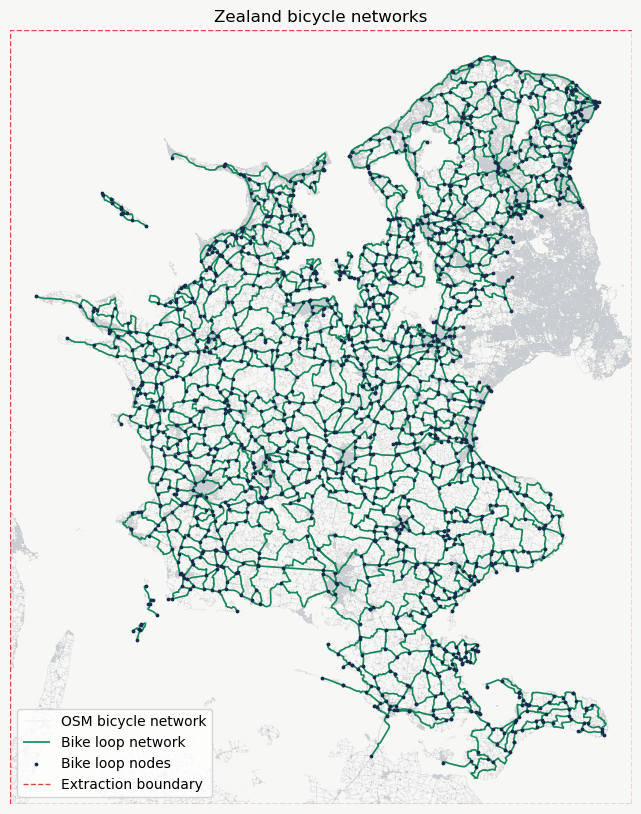

In [153]:
plot_bicycle_networks(
    sample=SAMPLE,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    bike_loops_bbox_gdf=bike_loops_bbox_gdf,
    osm_edges=osm_edges,
)

### Overlap analysis of the two bike networks

In [154]:
osm_spatial_index = osm_edges.sindex
matched_geometries, unmatched_geometries, matched_lengths, osm_candidate_counts = [], [], [], []

matched_osm_ids, matched_lit_values, matched_surface_values = [], [], []
number_of_edges = len(bike_loops_edges)

for position, geometry in enumerate(bike_loops_edges.geometry, start=1):

    # Find only OSM lines within the matching tolerance
    candidate_positions = osm_spatial_index.query(
        geometry,
        predicate="dwithin", # This predicate finds geometries that are within a specified distance of the input geometry.
        distance=TOLERANCE_M,
    )

    candidate_positions = np.unique(candidate_positions)
    
    candidates = osm_edges.iloc[candidate_positions]

    if candidates.empty:
        matched_geometry = shapely.GeometryCollection()
        unmatched_geometry = geometry

        matched_osm_id = np.nan
        lit_value = np.nan
        surface_value = np.nan

    else:
        # Calculate the complete matched geometry
        local_osm_network = shapely.union_all(candidates.geometry.array)
        local_osm_buffer = local_osm_network.buffer(TOLERANCE_M)
        matched_geometry = geometry.intersection(local_osm_buffer)
        unmatched_geometry = geometry.difference(local_osm_buffer)
        
        # Find which candidate covers the greatest
        # length of this bike-loop edge
        candidate_buffers = (
            candidates.geometry.buffer(
                TOLERANCE_M
            )
        )

        candidate_overlap_lengths = (
            candidate_buffers
            .intersection(geometry)
            .length
        )

        best_position = (
            candidate_overlap_lengths
            .to_numpy()
            .argmax()
        )

        best_candidate = candidates.iloc[best_position]

        matched_osm_id = best_candidate.get("id", np.nan)
        lit_value = best_candidate.get("lit", np.nan)
        surface_value = best_candidate.get("surface", np.nan)

    matched_geometries.append(matched_geometry)
    unmatched_geometries.append(unmatched_geometry)
    matched_lengths.append(matched_geometry.length)
    osm_candidate_counts.append(len(candidates))
    matched_osm_ids.append(matched_osm_id)
    matched_lit_values.append(lit_value)
    matched_surface_values.append(surface_value)

    if position % 500 == 0:
        print(f"Processed {position:,} of {number_of_edges:,} bike-loop edges")

print("Matching completed.")

Processed 500 of 2,589 bike-loop edges
Processed 1,000 of 2,589 bike-loop edges
Processed 1,500 of 2,589 bike-loop edges
Processed 2,000 of 2,589 bike-loop edges
Processed 2,500 of 2,589 bike-loop edges
Matching completed.


In [155]:
bike_loops_overlap = bike_loops_edges.copy()
bike_loops_overlap["bike_loop_length_m"] = (bike_loops_overlap.geometry.length)
bike_loops_overlap["matched_length_m"] = (matched_lengths)
bike_loops_overlap["unmatched_length_m"] = (bike_loops_overlap["bike_loop_length_m"] - bike_loops_overlap["matched_length_m"])
bike_loops_overlap["coverage_pct"] = (100 * bike_loops_overlap["matched_length_m"] / bike_loops_overlap["bike_loop_length_m"])
bike_loops_overlap["osm_candidate_count"] = (osm_candidate_counts)

bike_loops_overlap["matched_osm_id"] = (matched_osm_ids)
bike_loops_overlap["lit"] = (matched_lit_values)
bike_loops_overlap["surface"] = (matched_surface_values)

bike_loops_overlap["lit_group"] = (
    bike_loops_overlap["lit"].apply(
        group_lit
    )
)

bike_loops_overlap["surface_group"] = (
    bike_loops_overlap["surface"].apply(
        group_surface
    )
)

result_columns = [
    column
    for column in [
        "edge_id",
        "node_start",
        "node_end",
        "bike_loop_length_m",
        "matched_length_m",
        "unmatched_length_m",
        "coverage_pct",
        "osm_candidate_count",
        "matched_osm_id",
        "lit",
        "lit_group",
        "surface",
        "surface_group",
    ]
    if column in bike_loops_overlap.columns
]

matched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=matched_geometries,
    crs=BIKE_LOOPS_CRS,
)

unmatched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=unmatched_geometries,
    crs=BIKE_LOOPS_CRS,
)

matched_edges = matched_edges.loc[~matched_edges.geometry.is_empty].copy()
unmatched_edges = unmatched_edges.loc[~unmatched_edges.geometry.is_empty].copy()

print(f"Matched edges: {len(matched_edges):,}")
print(f"Edges with unmatched geometry: {len(unmatched_edges):,}")

Matched edges: 2,587
Edges with unmatched geometry: 213


Bike-loop length: 5,519.82 km
Matched length: 5,476.08 km
Unmatched length: 43.74 km
Coverage: 99.21%


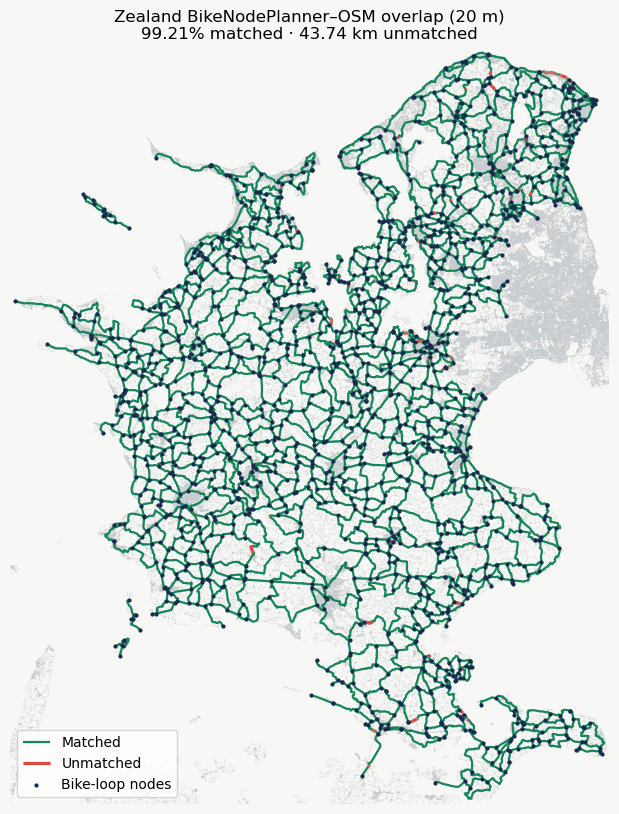

In [156]:
overlap_summary = plot_overlap_results(
    sample=SAMPLE,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    osm_edges=osm_edges,
    bike_loops_overlap=bike_loops_overlap,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
)

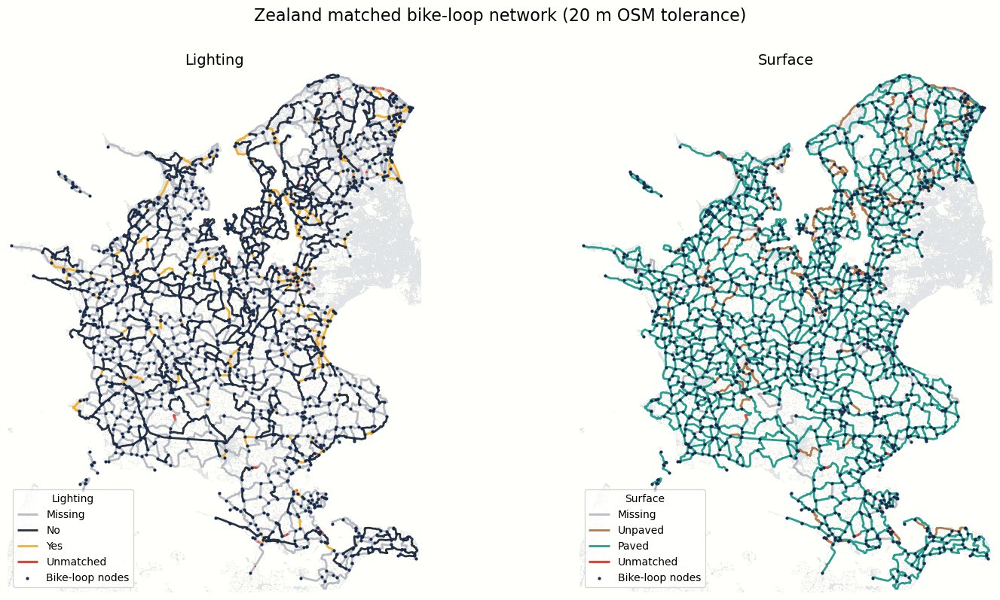

Saved: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/zealand/zealand_matched_lit_surface.png


In [157]:
fig, axes = plot_matched_attribute(
    sample=SAMPLE,
    osm_edges=osm_edges,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
)